# Food Health Analyser: Combined Dataset Preparation and Machine Learning Notebook

**Main objective:** This combined notebook prepares the KenyanFood13 image dataset and develops, evaluates and exports the food-image classification model for the Food Health Analyser. The machine-learning goal is to identify the most likely Kenyan food class from a meal photo and provide ranked top-three predictions that the mobile app can use as the starting point for retrieving the corresponding nutrition information.

> **Execution note:** The outputs already present in the two source notebooks have been retained in this combined notebook. They are saved results from the uploaded notebooks, not newly generated results from this merge. To reproduce or refresh them, run the notebook in a Kaggle environment with the KenyanFood13 competition dataset attached and a suitable GPU enabled. The source notebooks use Kaggle paths.


## Part A — Image dataset inspection, cleaning and preparation

This section inspects the KenyanFood13 image dataset, checks image integrity and duplicate records, reviews food labels, removes identified duplicates and questionable labels, and saves a cleaned image dataset for model training.

In [ ]:
import numpy as np
import pandas as pd
import os

# Data Description
## Source
Dataset: KenyanFood13, accessed on Kaggle through the competition “OpenCV Pytorch Course - Classification”https://www.kaggle.com/code/davidalford/kenyan-food-13

Original source: a research paper about scraping Instagram photos posted in Kenya to detect food types.

Licence or rules: Subject to competition rules

## Size and categories
8,174 photos in total, all .jpg, in 13 classes: bhaji, chapati, githeri, kachumbari, kukuchoma, mandazi, masalachips, matoke, mukimo, nyamachoma, pilau, sukumawiki, ugali.

train.csv has 6,536 labelled photos (columns id and class). test.csv has 1,638 rows.

Before cleaning, chapati had the most photos (862) and kukuchoma the fewest (173).

## Cleaning Summary
Original labelled photos: 6536 photos

After removing exact duplicates (23): 6513 photos

After removing near-duplicates (46): 6467 photos

After removing 7 wrongly labelled photos: 6467 photos

Missing labels: 0

Rows with no matching photo: 0

Repeated ids: 0

Corrupted photos: 0

Duplicates with conflicting labels: 0 (exact and near)

## Limits Encountered
Near-duplicates were found with a small image fingerprint, and we checked a few groups by eye rather than all of them.

Labels were checked by eye on 8 random photos per food (104 photos), so some wrong labels probably remain.

Many photos show several dishes, and some foods look alike.

We cleaned only the labelled photos. We never compared the test photos against the training photos for duplicates, so a few of them might be copies of the training photos. The test photos have no labels anyway.

## Citations
Anna Petrovicheva, Grigory Serebryakov, Pavel Semkin, Prakash Chandra, Satya Mallick, Sunita Nayak, and VikasGupta. OpenCV Pytorch Course - Classification. https://www.kaggle.com/competitions/pytorch-opencv-course-classification, 2020. Kaggle.


In [ ]:
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/opencv-pytorch-dl-course-classification"
train = pd.read_csv(DATA_DIR + "/train.csv")

print(train.shape)
train.head()

(6536, 2)


,id,class
0,14278962987112149800,githeri
1,13190220095752321996,ugali
2,10431803432626641638,kachumbari
3,4222441716327528413,githeri
4,2547906925836120627,matoke


In [ ]:
import os

# 1. How big is each file?
test = pd.read_csv(DATA_DIR + "/test.csv")
print("train rows:", len(train))
print("test rows:", len(test))
print("total:", len(train) + len(test))

# 2. Are any values missing?
print("\nMissing values:")
print(train.isna().sum())

# 3. How many photos per food?
print("\nPhotos per class:")
print(train["class"].value_counts())
print("Number of classes:", train["class"].nunique())

# 4. What do the photo file names look like?
print("\nFirst 5 files in images folder:")
print(os.listdir(DATA_DIR + "/images")[:5])

train rows: 6536
test rows: 1638
total: 8174

Missing values:
id       0
class    0
dtype: int64

Photos per class:
class
chapati        862
nyamachoma     784
bhaji          632
ugali          628
mandazi        620
kachumbari     494
matoke         483
githeri        479
masalachips    438
sukumawiki     402
pilau          329
mukimo         212
kukuchoma      173
Name: count, dtype: int64
Number of classes: 13

First 5 files in images folder:
['images']


In [ ]:
IMG_DIR = DATA_DIR + "/images/images"
files = os.listdir(IMG_DIR)

print("Files in folder:", len(files))
print("First 5 names:", files[:5])

# what file types are there?
from pathlib import Path
print("\nFile types:")
print(pd.Series([Path(f).suffix.lower() for f in files]).value_counts())

# does every id in train.csv have a matching photo?
file_ids = {Path(f).stem for f in files}
train_ids = set(train["id"].astype(str))
print("\nTrain ids with a photo:", len(train_ids & file_ids))
print("Train ids with NO photo:", len(train_ids - file_ids))

# repeated ids in the table?
print("Repeated ids in train.csv:", train["id"].duplicated().sum())

Files in folder: 8174
First 5 names: ['18286077912045734721.jpg', '10404026255145922708.jpg', '10287249802413271822.jpg', '18355411125526475604.jpg', '10536300270659742242.jpg']

File types:
.jpg    8174
Name: count, dtype: int64

Train ids with a photo: 6536
Train ids with NO photo: 0
Repeated ids in train.csv: 0


In [ ]:
from PIL import Image

# add the file path of each photo to the table
train["path"] = IMG_DIR + "/" + train["id"].astype(str) + ".jpg"

def check_image(path):
    try:
        with Image.open(path) as img:
            img.load()                       # forces the whole photo to be read
            return True, img.width, img.height
    except Exception:
        return False, None, None

results = train["path"].apply(check_image)
train["valid"]  = results.apply(lambda r: r[0])
train["width"]  = results.apply(lambda r: r[1])
train["height"] = results.apply(lambda r: r[2])

print("Photos that open fine:", train["valid"].sum())
print("Corrupted photos:", (~train["valid"]).sum())
train[["width", "height"]].describe()

Photos that open fine: 6536
Corrupted photos: 0


,width,height
count,6536.000000,6536.000000
mean,951.998623,940.528611
std,204.579015,243.655745
min,320.000000,168.000000
25%,720.000000,714.000000
50%,1080.000000,1080.000000
75%,1080.000000,1080.000000
max,1919.000000,1800.000000


In [ ]:
import hashlib

def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

train["md5"] = train["path"].apply(file_hash)

dup_mask = train.duplicated("md5", keep=False)
print("Photos involved in exact duplicates:", dup_mask.sum())
print("Extra copies that could be removed:", train.duplicated("md5").sum())

# are any copies filed under DIFFERENT food labels?
groups = train[dup_mask].groupby("md5")["class"].nunique()
print("Duplicate groups with conflicting labels:", (groups > 1).sum())

Photos involved in exact duplicates: 42
Extra copies that could be removed: 23
Duplicate groups with conflicting labels: 0


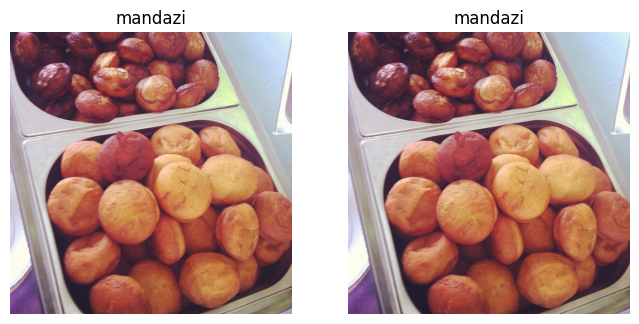

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

dups = train[dup_mask].sort_values("md5")
first_hash = dups["md5"].iloc[0]
group = dups[dups["md5"] == first_hash]

fig, axes = plt.subplots(1, len(group), figsize=(4 * len(group), 4))
for ax, (_, row) in zip(axes, group.iterrows()):
    ax.imshow(Image.open(row["path"]))
    ax.set_title(row["class"])
    ax.axis("off")
plt.show()

In [ ]:
clean = train.drop_duplicates("md5", keep="first").copy()

print("Before:", len(train))
print("After removing duplicates:", len(clean))

Before: 6536
After removing duplicates: 6513


In [ ]:
def dhash(path, size=8):
    with Image.open(path) as img:
        img = img.convert("L").resize((size + 1, size))   # tiny grayscale version
        px = list(img.getdata())
    bits = []
    for row in range(size):
        for col in range(size):
            left = px[row * (size + 1) + col]
            right = px[row * (size + 1) + col + 1]
            bits.append("1" if left > right else "0")
    return "".join(bits)

clean["dhash"] = clean["path"].apply(dhash)

near_mask = clean.duplicated("dhash", keep=False)
print("Photos involved in near-duplicates:", near_mask.sum())
print("Extra copies:", clean.duplicated("dhash").sum())

groups = clean[near_mask].groupby("dhash")["class"].nunique()
print("Groups with conflicting labels:", (groups > 1).sum())

/tmp/ipykernel_16/585598376.py:4: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  px = list(img.getdata())


Photos involved in near-duplicates: 91
Extra copies: 46
Groups with conflicting labels: 0


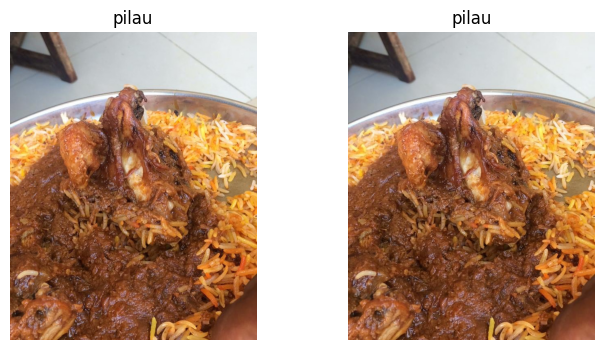

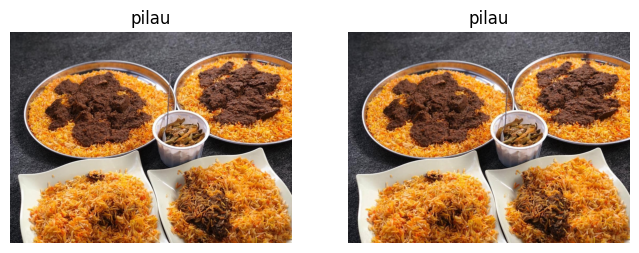

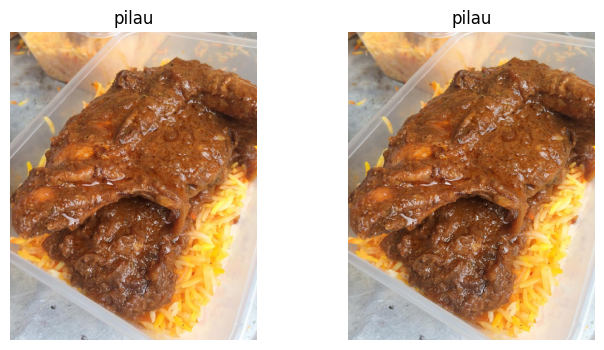

In [ ]:
near = clean[near_mask].sort_values("dhash")
hashes = near["dhash"].unique()[:3]          # first 3 groups

for h in hashes:
    group = near[near["dhash"] == h]
    fig, axes = plt.subplots(1, len(group), figsize=(4 * len(group), 4))
    if len(group) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, group.iterrows()):
        ax.imshow(Image.open(row["path"]))
        ax.set_title(row["class"])
        ax.axis("off")
    plt.show()

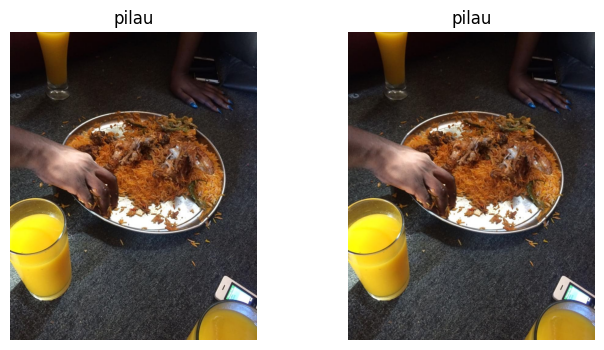

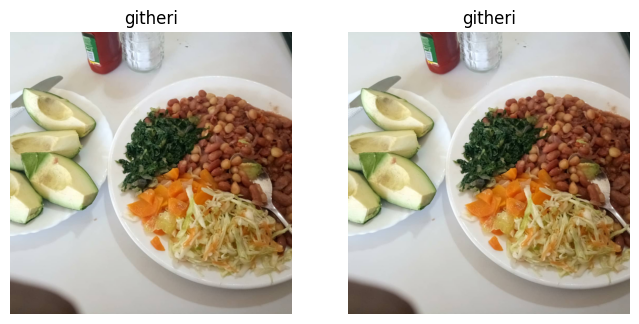

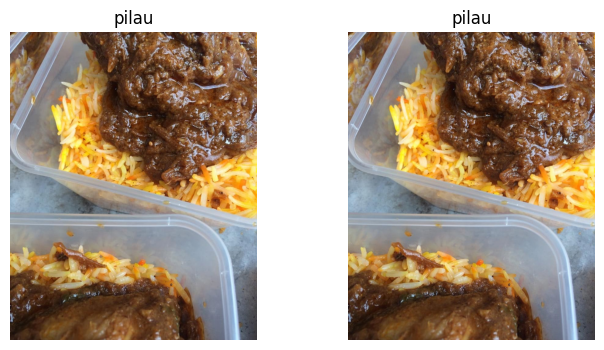

In [ ]:
near = clean[near_mask].sort_values("dhash")
hashes = near["dhash"].unique()[20:23]       # groups 21 to 23 instead of the first 3

for h in hashes:
    group = near[near["dhash"] == h]
    fig, axes = plt.subplots(1, len(group), figsize=(4 * len(group), 4))
    if len(group) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, group.iterrows()):
        ax.imshow(Image.open(row["path"]))
        ax.set_title(row["class"])
        ax.axis("off")
    plt.show()

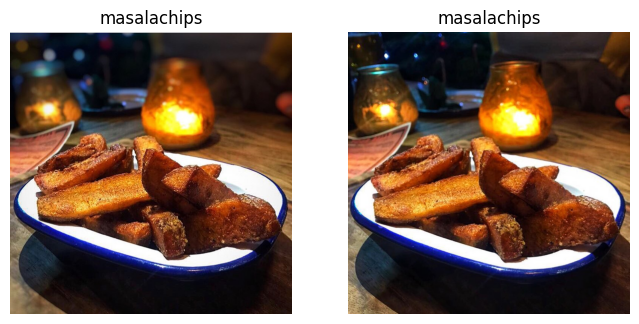

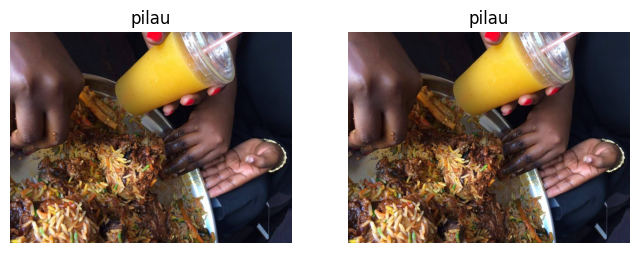

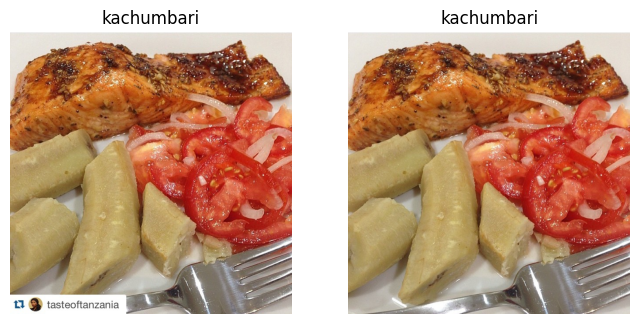

In [ ]:
near = clean[near_mask].sort_values("dhash")
hashes = near["dhash"].unique()[40:43]       # groups 21 to 23 instead of the first 3

for h in hashes:
    group = near[near["dhash"] == h]
    fig, axes = plt.subplots(1, len(group), figsize=(4 * len(group), 4))
    if len(group) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, group.iterrows()):
        ax.imshow(Image.open(row["path"]))
        ax.set_title(row["class"])
        ax.axis("off")
    plt.show()

In [ ]:
print("Before:", len(clean))
clean = clean.drop_duplicates("dhash", keep="first").copy()
print("After removing near-duplicates:", len(clean))

Before: 6513
After removing near-duplicates: 6467


['bhaji', 'chapati', 'githeri', 'kachumbari', 'kukuchoma', 'mandazi', 'masalachips', 'matoke', 'mukimo', 'nyamachoma', 'pilau', 'sukumawiki', 'ugali']


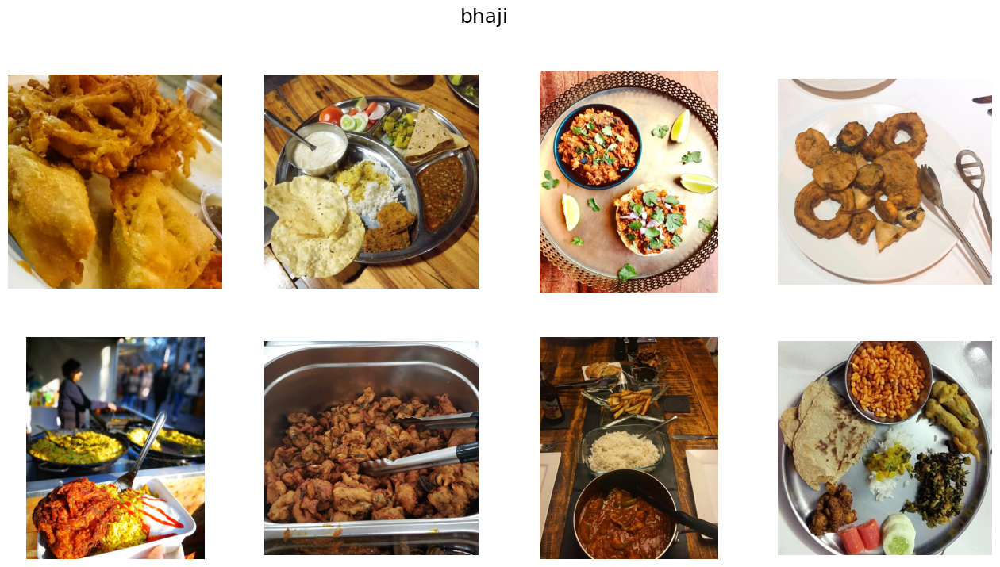

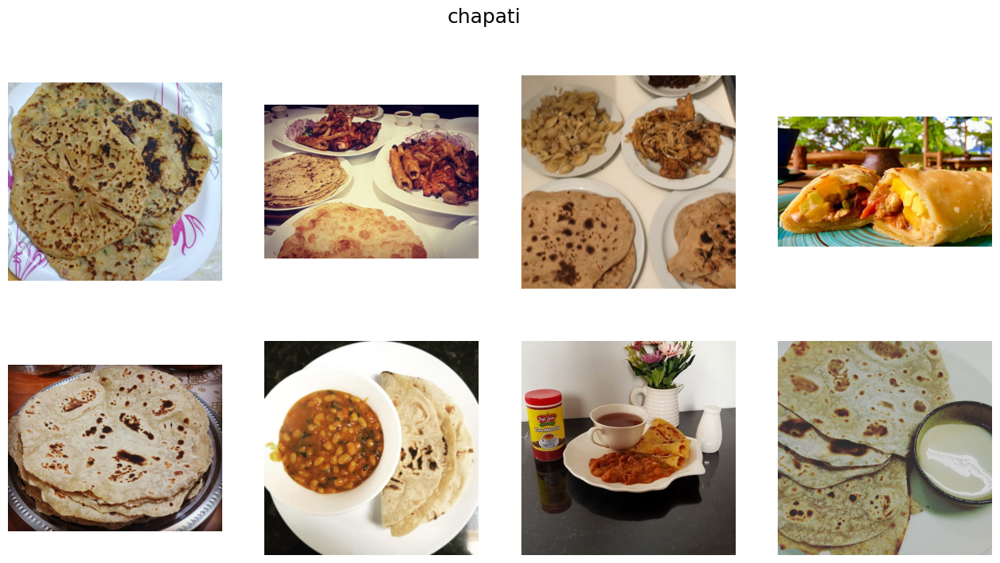

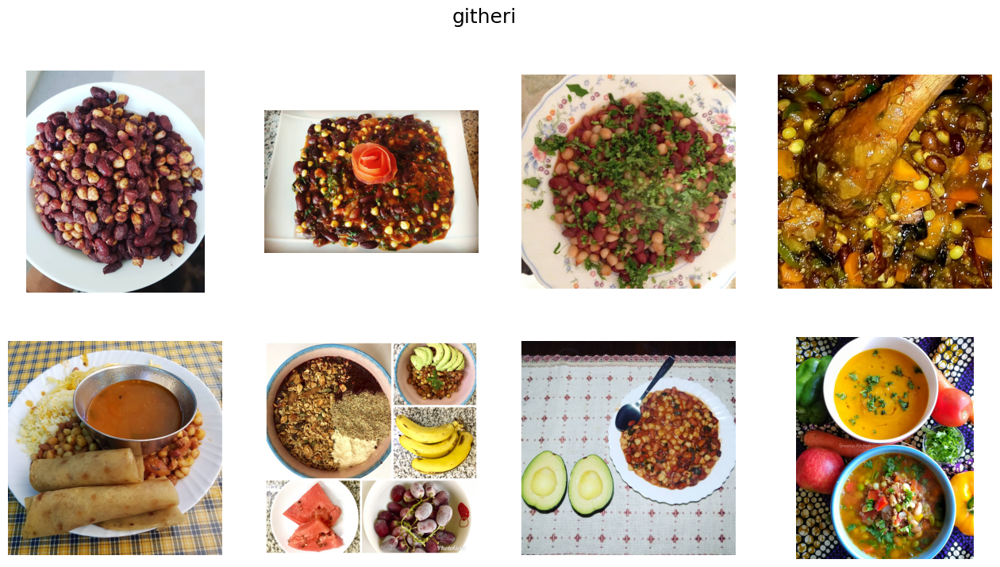

In [ ]:
def show_class(label, n=8, seed=1):
    subset = clean[clean["class"] == label]
    picks = subset.sample(n, random_state=seed)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for ax, (_, row) in zip(axes.flatten(), picks.iterrows()):
        ax.imshow(Image.open(row["path"]))
        ax.axis("off")
    fig.suptitle(label, fontsize=18)
    plt.show()

classes = sorted(clean["class"].unique())
print(classes)

for c in classes[:3]:
    show_class(c)

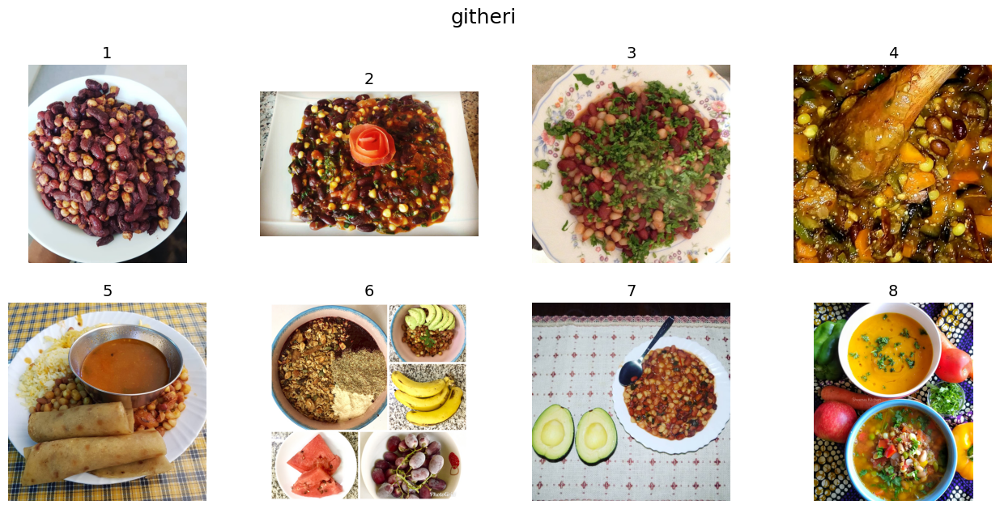

githeri ids in order: [13933805814784732224, 7137541340022629510, 15921367349081196982, 1149843062122526330, 4711295560881768278, 12860241446074944801, 4630248291925314477, 12944250541111215535]


In [ ]:
def show_class(label, n=8, seed=1):
    subset = clean[clean["class"] == label]
    picks = subset.sample(n, random_state=seed)
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for i, (ax, (_, row)) in enumerate(zip(axes.flatten(), picks.iterrows()), start=1):
        ax.imshow(Image.open(row["path"]))
        ax.set_title(str(i), fontsize=14)
        ax.axis("off")
    fig.suptitle(label, fontsize=18)
    plt.show()
    print(label, "ids in order:", list(picks["id"]))

show_class("githeri")

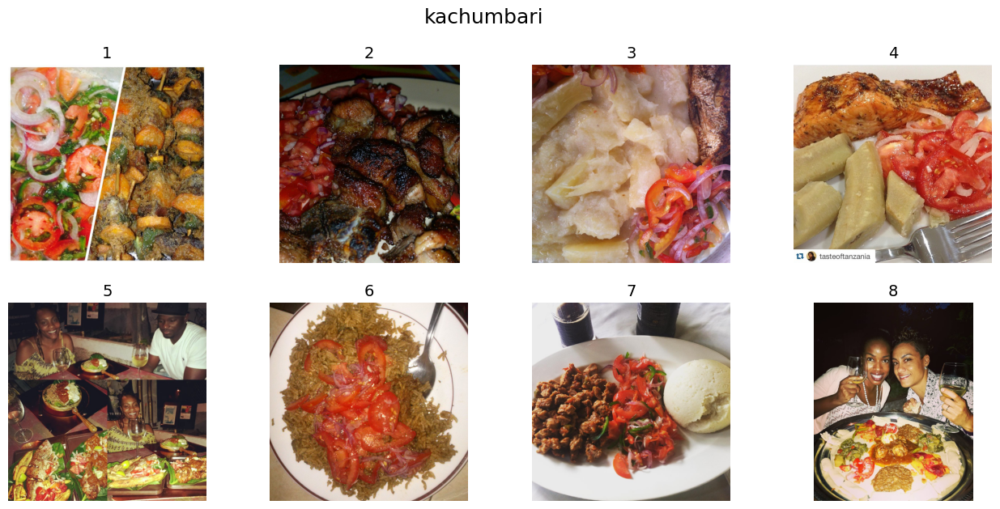

kachumbari ids in order: [15428588281804745041, 13615043203787961846, 1910544636328744125, 1962519694450856717, 3772707966978847729, 1452278469166113646, 1106073172962452688, 2430455914814818146]


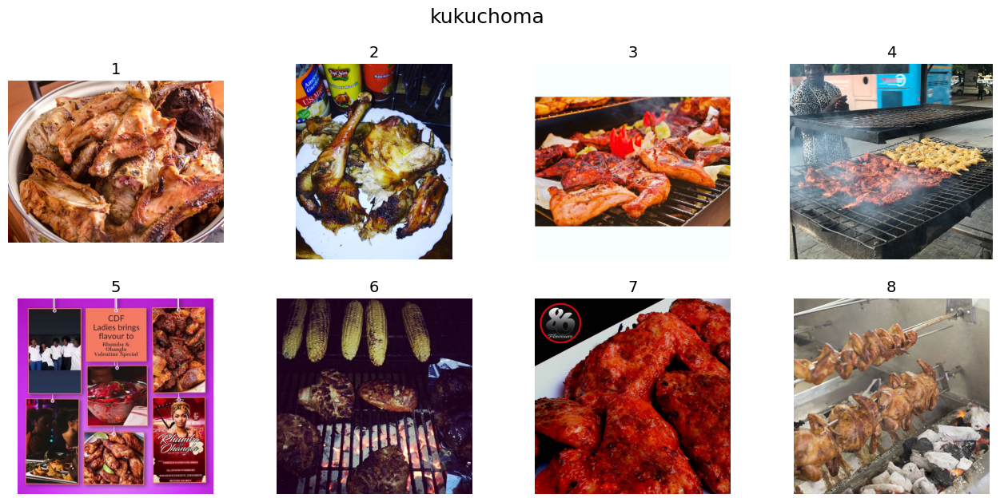

kukuchoma ids in order: [13602998598445397926, 4343006626070136589, 11555054859729866600, 15310997197388116873, 7986582846509328189, 7691994551500930371, 14807386907675098139, 10572504442007774389]


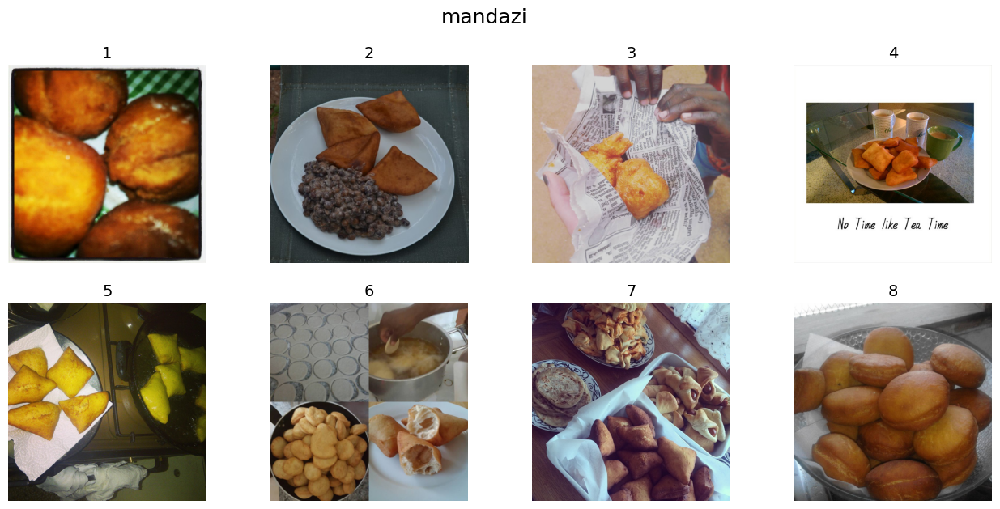

mandazi ids in order: [1870196241594106272, 6122615117770534687, 7521473190919770708, 16127098636929570534, 14984181710028766901, 2896133176207188076, 11848367800959951753, 11841874240824200844]


In [ ]:
for c in classes[3:6]:
    show_class(c)

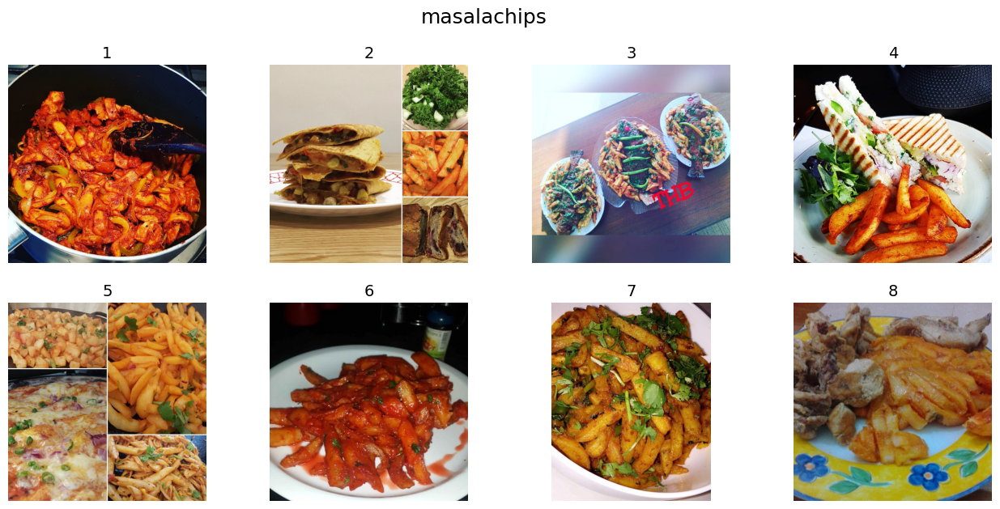

masalachips ids in order: [11148163536625448423, 10912699481353988585, 9387637575454788011, 14761848866868900696, 15769884802508044473, 1978415228297641634, 2313774463130787605, 13929103270128241250]


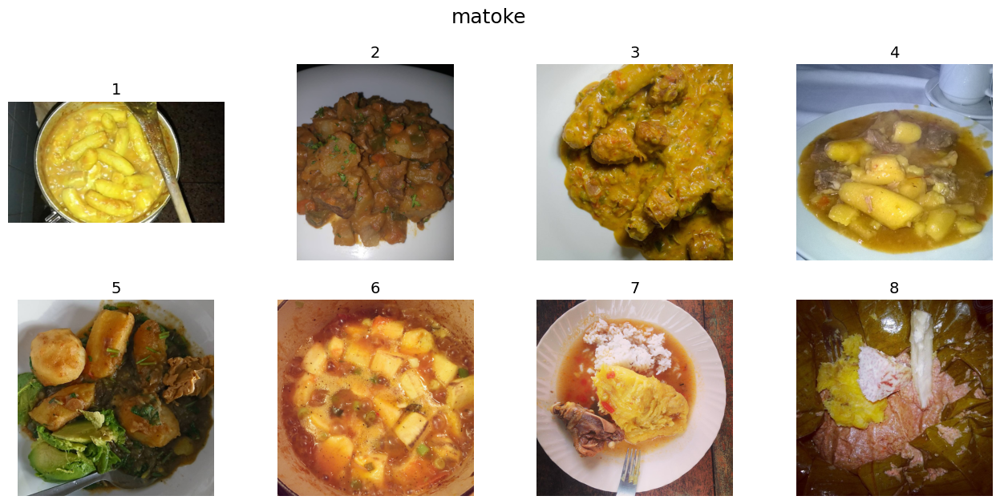

matoke ids in order: [4516492097593147027, 9577284489532451740, 7668438685451369431, 17809215060995737560, 8230860071058727563, 8982160267950962230, 8337296846883677359, 2800728609517992088]


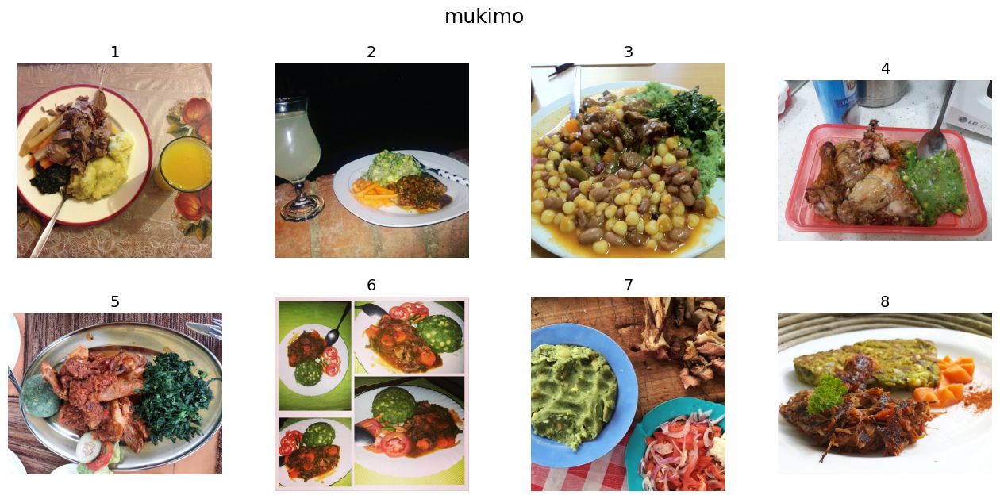

mukimo ids in order: [15892114759031138966, 6875531799312516842, 16972672631146526445, 7025428207417401593, 17741189736588788403, 15264688644071197922, 3832112412203160793, 4301026756657258050]


In [ ]:
for c in classes[6:9]:
    show_class(c)

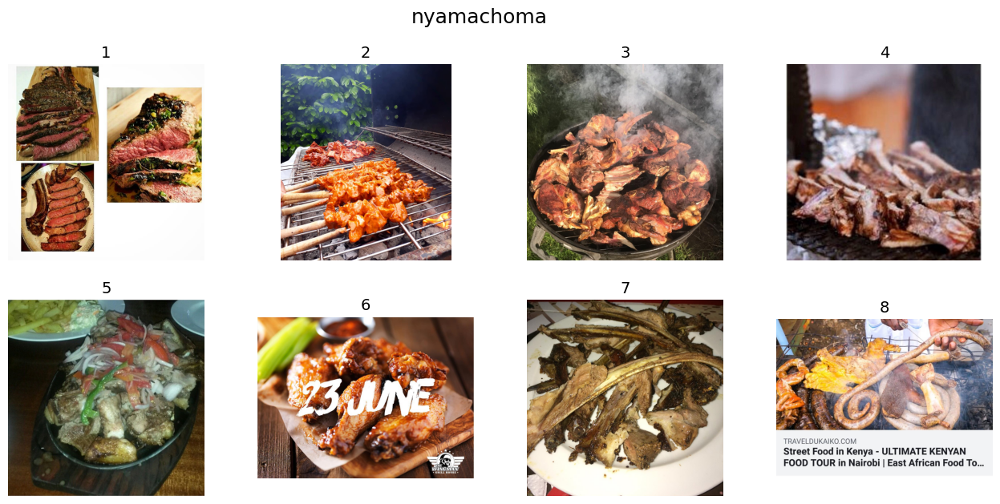

nyamachoma ids in order: [15494221505307396903, 13769081845140107993, 15397428584786118691, 15896061517598319958, 4165324532794490059, 1351828081220124776, 3815742673252153407, 14707234993054133912]


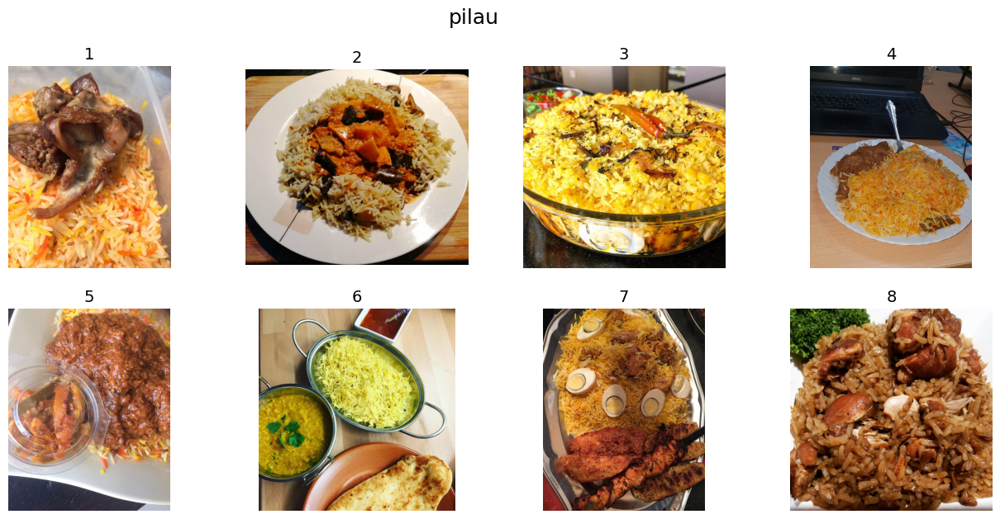

pilau ids in order: [17143162906213468292, 16718325454382529089, 13050540825015011303, 12310791247830006529, 9613751555954494194, 17630440806649713300, 229483083091880325, 5611122067531608155]


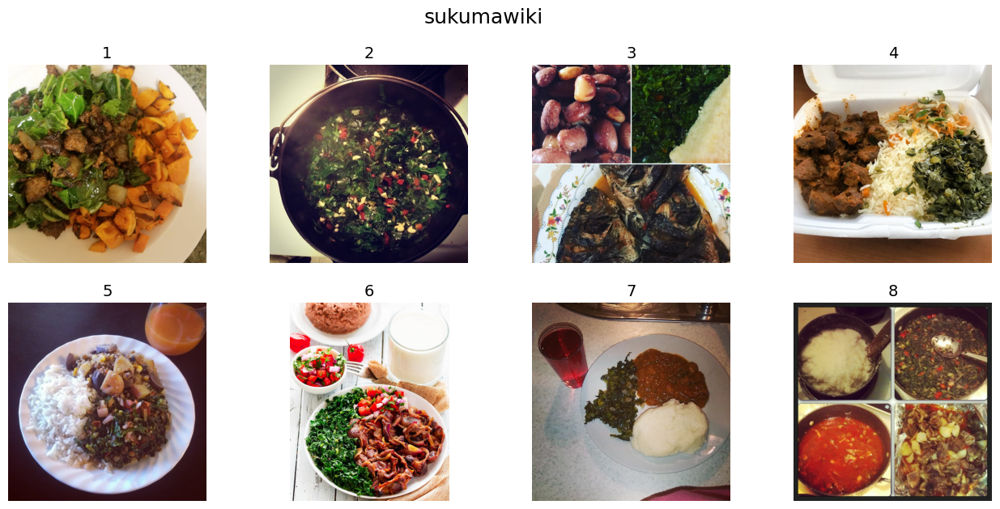

sukumawiki ids in order: [7491656162970214133, 14013606960939734251, 9982074675781874215, 17222295863452823019, 13790321767156763430, 459122275148527163, 15426604264879399583, 11011728505363359466]


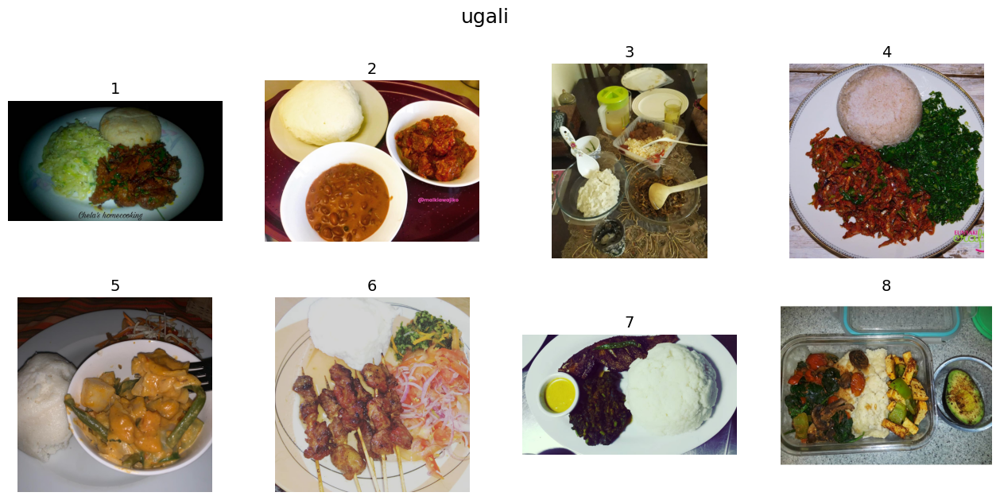

ugali ids in order: [5413119876456974778, 7673558291081750083, 7249265054392332051, 6344922520988378250, 4374191257768693511, 17613668885906195727, 14915431925607398021, 8388863161193387951]


In [ ]:
for c in classes[9:13]:
    show_class(c)

In [ ]:
to_check = {
    "githeri": [6, 8],
    "kachumbari": [5, 8],
    "kukuchoma": [5],
    "nyamachoma": [6],
    "mukimo": [3],
}

bad_ids = []
for label, numbers in to_check.items():
    picks = clean[clean["class"] == label].sample(8, random_state=1)
    for n in numbers:
        bad_ids.append(picks["id"].iloc[n - 1])

print(len(bad_ids), "photos selected")
print(bad_ids)

7 photos selected
[np.uint64(12860241446074944801), np.uint64(12944250541111215535), np.uint64(3772707966978847729), np.uint64(2430455914814818146), np.uint64(7986582846509328189), np.uint64(1351828081220124776), np.uint64(16972672631146526445)]


In [ ]:
print("Before:", len(clean))
clean = clean[~clean["id"].isin(bad_ids)].copy()
print("After:", len(clean))

Before: 6467
After: 6460


In [ ]:
os.makedirs("/kaggle/working/clean_data", exist_ok=True)

# the cleaned table: which photo has which label
clean[["id", "class", "width", "height"]].to_csv(
    "/kaggle/working/clean_data/clean_train.csv", index=False)

# your cleaning log as a small table
log = pd.DataFrame({
    "stage": ["Original labelled photos",
              "After removing exact duplicates",
              "After removing near-duplicates",
              "After removing wrongly labelled photos"],
    "photos": [6536, 6513, 6467, 6460]})
log.to_csv("/kaggle/working/clean_data/cleaning_log.csv", index=False)
print(log)

                                    stage  photos
0                Original labelled photos    6536
1         After removing exact duplicates    6513
2          After removing near-duplicates    6467
3  After removing wrongly labelled photos    6460


In [ ]:
import shutil

os.makedirs("/kaggle/working/clean_data/images", exist_ok=True)

for p in clean["path"]:
    shutil.copy(p, "/kaggle/working/clean_data/images/")

print("Photos copied:", len(os.listdir("/kaggle/working/clean_data/images")))

Photos copied: 6460


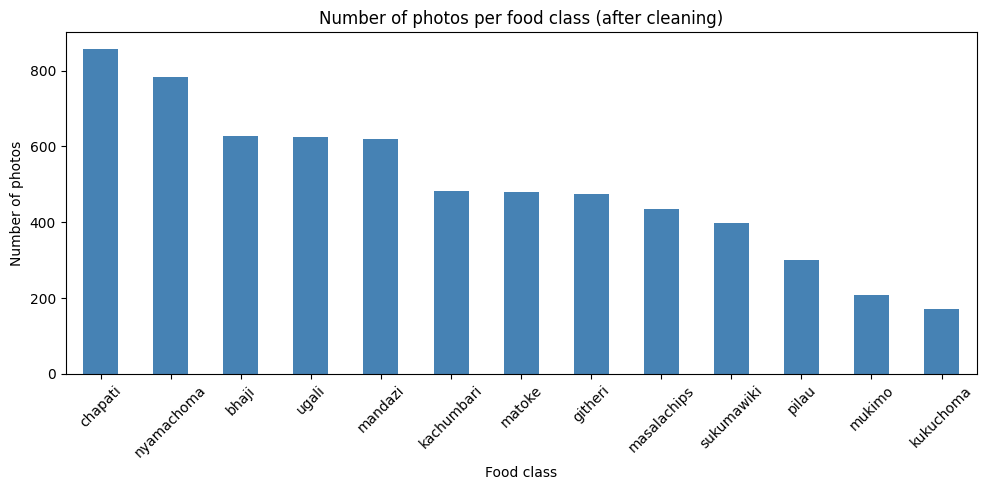

class
chapati        858
nyamachoma     782
bhaji          627
ugali          625
mandazi        619
kachumbari     482
matoke         479
githeri        474
masalachips    435
sukumawiki     399
pilau          301
mukimo         209
kukuchoma      170
Name: count, dtype: int64

Largest class: chapati 858
Smallest class: kukuchoma 170
Ratio largest : smallest = 5.0


In [ ]:
counts = clean["class"].value_counts()

counts.plot(kind="bar", figsize=(10, 5), color="steelblue")
plt.title("Number of photos per food class (after cleaning)")
plt.xlabel("Food class")
plt.ylabel("Number of photos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(counts)
print("\nLargest class:", counts.idxmax(), counts.max())
print("Smallest class:", counts.idxmin(), counts.min())
print("Ratio largest : smallest =", round(counts.max() / counts.min(), 1))

# Observation 1: Class Imbalance

Chapati and nyamachoma have the most photos (858 and 782, respectively), while kukuchoma has the fewest (170) in the dataset. See the chart above.

The ratio between the largest class and the smallest class is 5.0. Meaning the largest class has about 5 times as many photos as the smallest.

Mukimo (209) and kukuchoma (170) together hold only 379 photos, which is about 6% of the dataset. Chapati alone is about 13%.

A model could score well overall and still do poorly on kukuchoma because it accounts for a small percentage of the total. So we'd have to look at results per food, not just one overall number.

This ratio is high and might affect a model trained with this data. A model learns most from what it sees most, so it may get better at chapati than at kukuchoma.

The imbalance in the smaller classes could be handled by adding extra training photos.

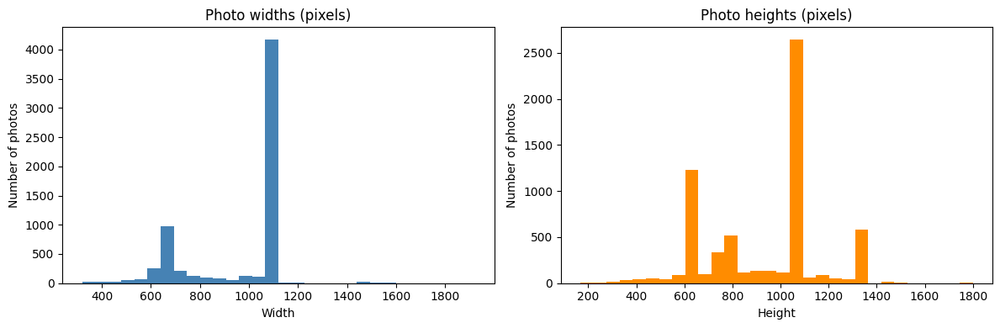

         width   height   aspect
count  6460.00  6460.00  6460.00
mean    952.58   940.58     1.04
std     204.61   243.52     0.19
min     320.00   168.00     0.80
25%     720.75   714.00     1.00
50%    1080.00  1080.00     1.00
75%    1080.00  1080.00     1.00
max    1919.00  1800.00     1.91

Photos exactly 1080 x 1080: 37.3 %
Photos with shorter side under 500 pixels: 2.4 %


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(clean["width"], bins=30, color="steelblue")
axes[0].set_title("Photo widths (pixels)")
axes[0].set_xlabel("Width")
axes[0].set_ylabel("Number of photos")

axes[1].hist(clean["height"], bins=30, color="darkorange")
axes[1].set_title("Photo heights (pixels)")
axes[1].set_xlabel("Height")
axes[1].set_ylabel("Number of photos")

plt.tight_layout()
plt.show()

clean["aspect"] = clean["width"] / clean["height"]
shorter = clean[["width", "height"]].min(axis=1)

print(clean[["width", "height", "aspect"]].describe().round(2))
print("\nPhotos exactly 1080 x 1080:",
      round(((clean["width"] == 1080) & (clean["height"] == 1080)).mean() * 100, 1), "%")
print("Photos with shorter side under 500 pixels:",
      round((shorter < 500).mean() * 100, 1), "%")

# Observation 2: Photo sizes and shapes vary
Most photos in the dataset are 1080 pixels wide. This is 4147 photos.

The photo heights are more mixed. The height chart has several spikes near 620, 800, 1080, and 1340, so photos share a width but come in different heights.

Photos that are exactly 1080x1080 are 37.3% (See chart).
Photos with a shorter side under 500 pixels are 2.4% (See chart).

A model requires every photo to be the same size, so you’ll have to resize them. Common choices are small squares, such as 224 × 224.

Forcing a wide photo into a square squizzes the food and changes its shape. Cropping the centre instead can cut food out of the picture. Both have a cost.

The photos are mostly large already, and only 2.4% are small. Few photos would need to be stretched up, which would make them blurry.

             before  after  removed  removed_pct
class                                           
pilau           329    301       28          8.5
kachumbari      494    482       12          2.4
kukuchoma       173    170        3          1.7
mukimo          212    209        3          1.4
githeri         479    474        5          1.0
bhaji           632    627        5          0.8
matoke          483    479        4          0.8
masalachips     438    435        3          0.7
sukumawiki      402    399        3          0.7
ugali           628    625        3          0.5
chapati         862    858        4          0.5
nyamachoma      784    782        2          0.3
mandazi         620    619        1          0.2

Total removed: 76


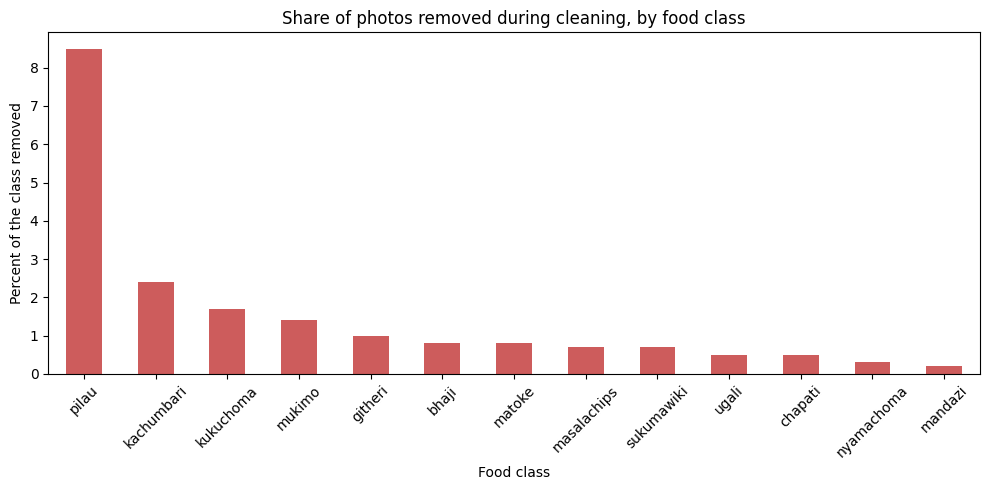

In [ ]:
before = train["class"].value_counts()
after = clean["class"].value_counts()

loss = pd.DataFrame({"before": before, "after": after})
loss["removed"] = loss["before"] - loss["after"]
loss["removed_pct"] = (loss["removed"] / loss["before"] * 100).round(1)
loss = loss.sort_values("removed_pct", ascending=False)
print(loss)
print("\nTotal removed:", loss["removed"].sum())

loss["removed_pct"].plot(kind="bar", figsize=(10, 5), color="indianred")
plt.title("Share of photos removed during cleaning, by food class")
plt.xlabel("Food class")
plt.ylabel("Percent of the class removed")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Observation 3: Pilau lost far more photos in cleaning than any other food
Pilau lost 28 photos, which is 8.5% of its original 329. (see chart above)

The next highest is kachumbari at 2.4%, and most foods lost 1% or less.(see chart above)

Therefore, pilau lost more than 3 times the share of any other food.(see chart above)

Pilau accounts for 28 of the 76 removed photos, about 37%, even though it’s a small class.

The imbalance from observation 1 didn’t change. Before cleaning, the ratio was about 5.0. After cleaning, it’s about 5.0.

Cleaning removed noise without fixing the imbalance.

## Possible reasons why Pilau lost the most photos
Some Pilau photos might have been posted multiple times, causing duplicates to occur.

Our near-duplicate check used a very small fingerprint, so it could be matching Pilau photos that only look similar (orange rice, the same sort of plate).

In [ ]:
print("Photos exactly 1080 wide:", (clean["width"] == 1080).sum())
print("As a share:", round((clean["width"] == 1080).mean() * 100, 1), "%")

Photos exactly 1080 wide: 4147
As a share: 64.2 %


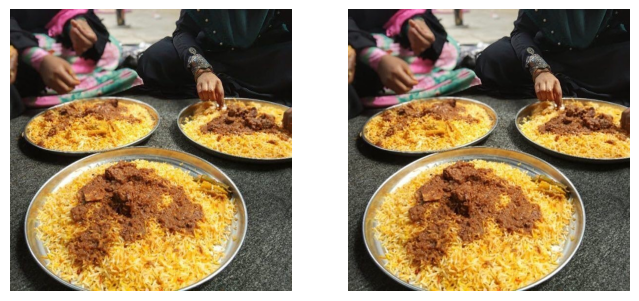

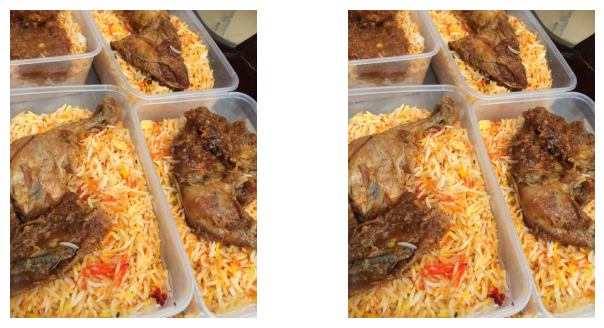

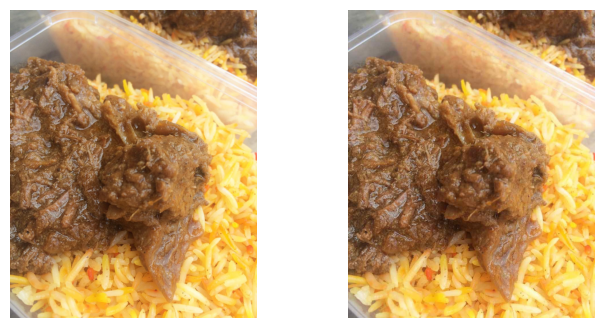

In [ ]:
pilau_near = near[near["class"] == "pilau"]
pilau_hashes = pilau_near["dhash"].unique()[3:6]

for h in pilau_hashes:
    group = pilau_near[pilau_near["dhash"] == h]
    fig, axes = plt.subplots(1, len(group), figsize=(4 * len(group), 4))
    if len(group) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, group.iterrows()):
        ax.imshow(Image.open(row["path"]))
        ax.axis("off")
    plt.show()

In [ ]:
print(pilau_near["dhash"].nunique())

17


In [ ]:
test = pd.read_csv(DATA_DIR + "/test.csv")
print(test.columns.tolist())
test.head()

['id']


,id
0,9156739011499789258
1,2049465964503133373
2,6446998501027132988
3,4194396063119815321
4,9018117998187006009


# Observation 4:
We looked at 8 random photos from each of the 13 foods, 104 in total.

7 photos were removed, which makes up 7% of the sample.

A collage with granola, avocado and bananas, and a photo of two soups, both labelled githeri.

A photo of people at a restaurant table with barely any food, and another of two women toasting, both labelled kachumbari.

An event flyer with text, labelled kukuchoma.

 A promo poster with "23 JUNE" across chicken wings, labelled nyamachoma.

 A plate that looked like beans and maize, labelled mukimo.

 Doubtful photos we kept: one ugali photo that may be a cauliflower, and two masalachips photos that may be pasta.

 Many photos with several dishes on one plate, like ugali with suskuma wiki and meat.

 ## Foods that look similar
 Nyamachoma and kukuchoma are both grilled meat.

 Githeri and mukimo both have beans and maize.

 A model learns from the label attached to each photo, so a photo with the wrong label could teach it the wrong thing from what is in the photo.

 When a photo shows multiple foods but one label, the model may not tell which food the label means.

 Because nyamachoma and kukuchoma look similar to me, a model may mix them up.


In our sample, 7 of 104 photos were clearly wrong. A likely reason is that the photos were collected from Instagram using keyword searches, so people attach a food name to a post even when the photo isn’t really that food.

## Limits to our check:
During our check, we only looked at 8 photos per food, which makes that 104 out of 6,460. This is about 1.6% of our dataset.

Only we judged the photos, so others might disagree with us.

Some foods in some photos didn't look like the correct one according to the label. For example, in one photo, the ugali resembled a cauliflower, which might be true.

The 7% applies to our sample only, so we can't say 7% of all photos are wrong. Some wrong labels probably remain.





## Part B — Multi-class food image classification

This section uses the cleaned dataset produced in Part A to train and evaluate a pretrained EfficientNetV2-B2 classifier. It uses a stratified train/validation/test split, image augmentation and class weights, then compares the pretrained model with an optimised CNN trained from scratch. The final steps test predictions, export the model to TensorFlow Lite, and assess whether it is suitable for mobile integration.

# Food Health Analyzer
# Phase 1: A Pretrained Multi-class Label Food Classifier (Top-3 Guesses)

- **Project:** Kenyan food recognition (13 classes) for the mobile app
- **Goal of this notebook:** go from the ~32-34% base CNN to a model that reaches high accuracy, shows **3 guesses with percentages**, can be tested on **our own photos**, and is exported as **TFLite** for the Kotlin app.

### Before you run anything (Kaggle settings, right-hand panel)
1. **Accelerator -> GPU T4 x2 (or P100).** Training on CPU will take hours.
2. **Internet -> On.** The pretrained weights (ImageNet) are downloaded the first time we build the model.
3. **Add Input -> Notebook -> FoodAppDataset_Notebook** (Asiya's cleaned data), as in her instructions.
4. **Check the `FINAL_RUN` switch in Step 1.** `False` = tuning run (train / validation / test). `True` = final run (the validation photos join the training set). A full run takes roughly 1 hour 40 minutes on Kaggle.

### Roadmap
| Step | What happens |
|---|---|
| 1 | Setup, settings (including the `FINAL_RUN` switch) and imports |
| 2 | Load Asiya's cleaned data and check every file exists |
| 3 | Duplicate check (to make sure test accuracy is honest) |
| 4 | Train / validation / test split (70/15/15; 85/15 in the final run) |
| 5 | Build the image pipeline with augmentation and class weights |
| 6 | Build the pretrained model (EfficientNetV2-B2) |
| 7 | Stage 1: train the new head only |
| 8 | Stage 2: fine-tune the top of the backbone |
| 9 | Evaluate: top-1, top-3, macro F1, confusion matrix |
| 10 | Test with **our own photos** |
| 11 | Export `.tflite` + `labels.txt` for the mobile app |
| 12 | Control experiment: a highly optimised CNN built from scratch |
| 13 | Evidence: pretrained model vs scratch CNN (charts + table) |

## Reading the numbers: what the lecturer told us, and what accuracy we can honestly aim for

**"32% means your base CNN is underfitting."**
Underfitting means the model is *learning too little*: it scores poorly on the photos it trained on **and** on photos it has never seen, and the gap between the two is small. Overfitting is the opposite: very high training accuracy but low accuracy on unseen photos.

Our own runs show the first pattern. The optimised scratch CNN (Step 12) finished 40 epochs at about 40% training accuracy and 33% validation accuracy (training loss 2.03 vs validation loss 2.16) and scored 40.35% top-1 on the test set. It was not memorising the photos; it had not yet learned what they look like. The pretrained model showed the same thing in Stage 1, where the backbone was frozen and only the new head could learn: 62.5% train vs 64.9% validation.

Accuracy rose when we gave the model more ability to learn: a pretrained EfficientNetV2-B2 backbone, 260px images, fine-tuning the top 120 backbone layers, and longer training. After fine-tuning, training accuracy reached 83.7% and validation accuracy 75.9%, a normal gap of about 8 points. We did not test these changes one at a time, so we cannot say how much each one contributed.

**Data split.** While tuning (`FINAL_RUN = False`) the cleaned data is split 70% train / 15% validation / 15% test (4,522 / 969 / 969 photos). In the final run (`FINAL_RUN = True`) the validation photos are merged into training (5,491 photos, 85%) and the same 969 test photos (15%) give the one-time final score.

**What accuracy can we honestly aim for?**
This dataset is **KenyanFood13**. The authors who published it reported about **81% top-1 accuracy**, but their model used the **image plus the Instagram caption**. Their own ablation showed captions added about 9 percentage points, which puts an **image-only** model at roughly **72%** (our own estimate: 81% minus 9 points). Our app only has the photo, so:

* **Top-1 accuracy (is the first guess right?)**: our target was 70% or higher, which is close to what an image-only model can be expected to reach on this dataset.
* **Top-3 accuracy (is the right food among the 3 guesses?)**: this is the metric that matches our app, because the app shows 3 guesses and lets the user correct it.

**Result (saved run, `FINAL_RUN = False`):** 71.93% top-1, 94.53% top-3 and 0.702 macro F1 on the 969 test photos (Step 9, with flip averaging).

We report **both** accuracy numbers, plus **macro F1** (which treats rare classes like kukuchoma and mukimo fairly instead of letting the big classes hide weak spots).

## Why we use Asiya's single-labelled data (and not a new multi-label dataset)

1. **There is no public multi-label Kenyan food dataset.** KenyanFood13 itself was released because no Kenyan food image dataset existed. The multi-label African-food datasets we found are Nigerian and tiny (for example CHOWNET-V1 has only 118 images and different foods), so they cannot teach our 13 Kenyan classes.
2. **Asiya's cleaning is already done and was marked well.** Re-cleaning something else would cost hours and would make our results harder to compare with the team's.
3. **Time and comparability.** We use the same cleaned data and the same split (70/15/15, seed 42) as the team's base CNN, so the test photos are the same and the scores can be compared directly.

**The honest trade-off:** many photos show a *whole plate* (e.g. pilau with beef and a side) but carry only *one* label. That is **label noise**, and it puts a ceiling on single-label accuracy. Our confusion results show it: many of the biggest mistakes are foods that are served together, such as ugali and sukumawiki (Step 9). We handle this in two steps:

* **Now (this notebook):** train with one label per image, but show the **top-3 guesses** so a plate with several foods can still surface them.
* **Next:** hand-label a small set of real plates with several foods each (multi-hot labels) and train a **sigmoid multi-label head**, so each food gets its own independent probability. That is true multi-label learning, and we only need a small set of plate photos for it because the pretrained backbone does the heavy lifting.

## Why a pretrained model instead of a CNN from scratch

#### Analogy
Think of a chef-in-training. A scratch CNN is someone who has never seen any food and must learn what colour, texture and shape even mean from a few thousand photos. A **pretrained** model is someone who has already looked at **over a million photos** (ImageNet) and learned edges, textures, grains, sauces, round vs flat shapes. We only teach them the last bit: "these specific textures mean *ugali*, those mean *githeri*".

This is called **transfer learning**, and it works because the early layers learn general visual features that are useful for almost any image task. Benefits for us:

* it **learns much more from the same photos**: the scratch CNN stalled at about 40% training accuracy (underfitting, Step 12), while the pretrained model reached 83.7% training and 75.9% validation accuracy;
* much **higher accuracy** from the same photos (71.93% top-1 vs 40.35% for the best scratch CNN we built, saved run);
* **EfficientNetV2-B2 is small enough for a phone**: about 8.8 million parameters and a 9.7 MB TFLite file, so it fits our Kotlin app (on-device speed is still to be measured).

We train in **two stages**: first only the new classification head (backbone frozen), then a gentle **fine-tune** of the top 120 backbone layers at a small learning rate (2e-5) so the model adapts to Kenyan food without destroying what it already knows.

# Developing Multi-class Label ML

## Step 1 - Setup, settings and imports

We fix a **random seed** so that results are reproducible (same split, same shuffling every run). The settings at the top of the cell control the whole notebook:

* `IMG_SIZE = 260`: every photo is resized to 260x260, a balance between food detail and training time (the team's base CNN used 128px, which throws detail away).
* `BACKBONE = "EfficientNetV2B2"`: the pretrained model we build in Step 6.
* `UNFREEZE_LAST = 120`: how many of the backbone's last layers are fine-tuned in Stage 2 (Step 8).
* `STAGE1_EPOCHS = 15` and `STAGE2_EPOCHS = 35`: how long each training stage runs.
* `FINAL_RUN`: the **tuning / final switch**. `False` = train + validation + test (70/15/15): we watch validation accuracy to choose the epoch counts. `True` = the validation photos are merged into training (85% train, 15% test) and the model trains for the fixed epoch counts. The 969 test photos are the same in both modes, so the scores can be compared.

In [6]:
import os, json, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

import glob

# Reproducability: same seed gives the same split and shuffling on every run, avoiding random sequences onevery re-run after training
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 260    # Efficient NetV2 size which is slightly more efficient than 224
BATCH = 32       # images processed per training step
BACKBONE = "EfficientNetV2B2" # Suitable/Firendly for Mobile
UNFREEZE_LAST = 120
FINAL_RUN = False
# False: Train + test only(no Validation split)
# True: Train + validation + test
STAGE1_EPOCHS = 15
STAGE2_EPOCHS = 35

print("TensorFlow: ", tf.__version__)
print("GPUs found: ", tf.config.list_physical_devices("GPU"))   # should not be empty to enable this notebook to run smoothly

TensorFlow:  2.21.0
GPUs found:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Step 2 - Load Asiya's cleaned data

`clean_train.csv` has one row per photo: `id`, `class`, `width`, `height`. The photo itself is `images/<id>.jpg`. We build the full path for each row and **check the file really exists**, because a single missing file would crash training halfway through.

In [ ]:
# Load the cleaned dataset created in Part A of this combined notebook.
# The first path is the output produced by Part A in the current Kaggle session.
# The second path is retained as a fallback for the original separately saved dataset.

candidate_paths = [
    "/kaggle/working/clean_data/clean_train.csv",
    "/kaggle/input/notebooks/asiyaabdalla/foodappdataset-notebook/clean_data/clean_train.csv",
]

hits = [p for p in candidate_paths if os.path.exists(p)]
print("Available cleaned CSV:", hits)

if not hits:
    raise FileNotFoundError(
        "clean_train.csv was not found. Run Part A first, or attach the "
        "cleaned dataset to Kaggle and update candidate_paths."
    )

BASE = os.path.dirname(hits[0])
print("BASE =", BASE)

IMG_DIR = os.path.join(BASE, "images")
df = pd.read_csv(os.path.join(BASE, "clean_train.csv"))
df["path"] = df["id"].astype(str).apply(lambda i: os.path.join(IMG_DIR, i + ".jpg"))

exists = df["path"].apply(os.path.exists)
print("Rows in CSV:", len(df))
print("Rows with a matching image:", exists.sum())

# Keep only rows whose image files exist (safety net)
df = df[exists].reset_index(drop=True)

print("\nPhotos per class (note the imbalance):")
print(df["class"].value_counts())


## Step 3 - Duplicate check (so our test score is honest)

If the **same photo** ends up in both the training set and the test set, the model has effectively "seen the exam", and the test accuracy is **inflated** (this is called **data leakage**).

We compute an **MD5 fingerprint** of every file. Identical files have identical fingerprints. This only catches **exact** copies, not near-duplicates (e.g. the same photo re-cropped or re-saved), but it is a quick and valuable check.

**Result:** 0 exact duplicates and 0 fingerprints with conflicting labels, so all 6,460 cleaned photos are kept.

In [8]:
def file_hash(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()
df["hash"] = df["path"].apply(file_hash)

dup_mask = df.duplicated("hash", keep="first")
print("Exact duplicate photos found: ", dup_mask.sum())

# Checking whether identical photos carry different labels(label conflicts)
conflicts = df.groupby("hash")["class"].nunique()
print("Fingerprints with conflicting labels:", (conflicts > 1).sum())

# Remove the extra copies (keep the first of each)
df = df[~dup_mask].reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Exact duplicate photos found:  0
Fingerprints with conflicting labels: 0
Rows after removing duplicates: 6460


## Step 4 - Train / validation / test split (70 / 15 / 15, or 85 / 15 in the final run)

**Tuning run (`FINAL_RUN = False`):**
* **Train (70%, 4,522 photos)**: the model learns from these.
* **Validation (15%, 969 photos)**: we watch this during training to see whether the model is still learning, to spot overfitting if it appears, and to decide when to stop and how many epochs to use.
* **Test (15%, 969 photos)**: touched **once**, at the end, for the final honest score.

**Final run (`FINAL_RUN = True`):** the validation photos are merged into the training set (5,491 photos, 85%), because we no longer need to tune and more training photos generally help a model that was learning too little. There is no validation set, so the model trains for the fixed epoch counts found in the tuning run, and the **same 969 test photos** give the score.

`stratify` keeps the class proportions the same in every part (important because chapati has ~5x more photos than kukuchoma). Same `seed=42` as the team's split.

In [9]:
class_names = sorted(df["class"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)
df["label"] = df["class"].map(class_to_idx)

print("Classes (index order the model will use):")
for i, c in enumerate(class_names):
    print(i, c)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

print("\nTrain: ", len(train_df), " Val: ", len(val_df), " Test: ", len(test_df))

Classes (index order the model will use):
0 bhaji
1 chapati
2 githeri
3 kachumbari
4 kukuchoma
5 mandazi
6 masalachips
7 matoke
8 mukimo
9 nyamachoma
10 pilau
11 sukumawiki
12 ugali

Train:  4522  Val:  969  Test:  969


## Step 5 - The image pipeline (loading, resizing, augmentation, class weights)

**Loading and resizing.** Photos have different shapes (1080x843, 1080x1350, ...). We resize every photo to 260x260 (`IMG_SIZE`). This slightly squashes the aspect ratio, which is a common, acceptable trade-off for classification (we keep the full photo instead of cropping away food at the edges). Each photo is decoded and resized **once** and kept in memory as small 0-255 integers, so later epochs only pay for the augmentation.

**Augmentation.** Each epoch the model sees a *slightly different version* of every training photo: flipped (left-right and up-down), rotated by up to ~90 degrees, zoomed, shifted, and made brighter, darker, or higher/lower contrast. Plates are photographed from above at any angle, so this teaches the model that a food is the same food whichever way the plate is turned (for example a folded chapati vs a mandazi). It also stops the model memorising exact pixels. We apply it to **training images only**, never to validation or test, because those must stay untouched to give honest scores. Because training photos are augmented (and dropout is on), the *training accuracy* printed during training is a little lower than it would be on clean photos, so validation accuracy can sit slightly above it early on.

**Class weights (fights imbalance).** Kukuchoma has far fewer photos than chapati. We give rare classes a **bigger weight in the loss** (in the tuning run: kukuchoma 2.92, mukimo 2.38, chapati 0.58), so mistakes on them cost more and the model does not just favour the big classes. The side effect is visible in Step 9: kukuchoma is found more often (recall 0.58) but is also predicted for photos that are not kukuchoma (precision 0.31).

**Note:** we do *not* normalise pixels here. The normalisation is built **inside the EfficientNetV2 backbone** (`include_preprocessing=True`, Step 6), so the exported TFLite model accepts plain 0-255 pixels and the Kotlin app does not have to repeat the same maths (a classic source of bugs).

Class weights: {'bhaji': 0.79, 'chapati': 0.58, 'githeri': 1.05, 'kachumbari': 1.03, 'kukuchoma': 2.92, 'mandazi': 0.8, 'masalachips': 1.14, 'matoke': 1.04, 'mukimo': 2.38, 'nyamachoma': 0.64, 'pilau': 1.65, 'sukumawiki': 1.25, 'ugali': 0.79}


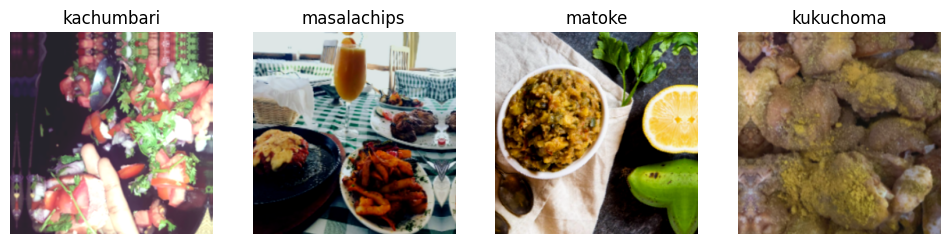

In [10]:
# -- Stronger augmentation: shape/orientation invariance (folded chapati vs mandazi) --
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),   # plates are photographed from above, any orientation
    layers.RandomRotation(0.25),                    # up to ~90 degrees
    layers.RandomZoom((-0.25, 0.15)),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
], name="augment")

fit_df = pd.concat([train_df, val_df]) if FINAL_RUN else train_df
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=fit_df["label"].values)
cw_tensor = tf.constant(cw, dtype=tf.float32)
print("Class weights:", {class_names[i]: round(float(w), 2) for i, w in enumerate(cw)})

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.round(img), tf.uint8), label      # uint8 = small enough to cache in RAM

def make_ds(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label"].values))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()   # decode JPEGs only once
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), tf.one_hot(y, NUM_CLASSES)),
                num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH)
    if training:
        def aug_and_weight(x, y):
            x = tf.clip_by_value(augment(x, training=True), 0.0, 255.0)
            w = tf.gather(cw_tensor, tf.argmax(y, axis=1))
            return x, y, w
        ds = ds.map(aug_and_weight, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(fit_df, training=True)
val_ds   = make_ds(val_df, training=False)
test_ds  = make_ds(test_df, training=False)

imgs, labels, _ = next(iter(train_ds))
plt.figure(figsize=(12,3))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.imshow(imgs[i].numpy().astype("uint8"))
    plt.title(class_names[int(tf.argmax(labels[i]))]); plt.axis("off")
plt.show()

## Step 6 - Build the pretrained model (EfficientNetV2-B2)

Our first version used MobileNetV2 at 224px and scored **62.85% top-1** on the test set. The final model uses **EfficientNetV2-B2 at 260px**, with stronger augmentation, deeper fine-tuning and flip averaging, and scores **71.93%** (saved run). We did not test each change separately, so we cannot say how much each one contributed.

The model is a sandwich:

1. **Input**: a 260x260 colour photo with plain 0-255 pixels.
2. **EfficientNetV2-B2 backbone** (pretrained on ImageNet). `include_top=False` removes its original 1000-class ending, and `include_preprocessing=True` builds the pixel scaling into the backbone. It holds about 8.77 million of the model's 8.79 million parameters.
3. **GlobalAveragePooling**: squeezes the feature maps into one vector (1,408 numbers) per image.
4. **Dropout (0.4)**: randomly switches off 40% of units during training, a light regulariser.
5. **Dense(13, softmax)**: our new head (18,317 parameters). **Softmax** turns 13 raw scores into 13 probabilities that add up to 100%, which is exactly what we need to show "ugali 71%, githeri 14%, matoke 6%".

`base.trainable = False` **freezes** the backbone for now, so only the new head learns. `training=False` when calling the backbone keeps its **BatchNorm** layers in inference mode, which stops them from being disturbed by our small dataset.

**Loss: categorical cross-entropy with label smoothing (0.1).** Instead of telling the model "this is 100% ugali", we say "~91% ugali, a little spread over the rest". That is kinder to our noisy labels (plates with several foods) and tends to give better-calibrated percentages.

In [11]:
base = getattr(keras.applications, BACKBONE)(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)
base.trainable = False # freeze the pretrained backbone for Stage 1

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x= layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="food_probs")(x)
model = keras.Model(inputs, outputs, name=f"kenyan_food_{BACKBONE.lower()}")


def compile_model(lr):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),                # top -1
            keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_accuracy"),  # top-3
        ],
    )

compile_model(1e-3)
model.summary()

35839040/35839040 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "kenyan_food_efficientnetv2b2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 260, 260, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b2 (Functional)  │ (None, 9, 9, 1408)     │     8,769,374 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1408)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ food_probs (Dense)              │ (None, 13)             │        18,317 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,787,691 (33.52 MB)

 Trainable params: 18,317 (71.55 KB)

 Non-trainable params: 8,769,374 (33.45 MB)

## Step 7 - Stage 1: train the new head (backbone frozen)

Learning rate **1e-3** is fairly large, which is fine because only the small new head is learning from scratch. We train for up to `STAGE1_EPOCHS = 15` epochs.

Two helpers keep training safe (tuning run, `FINAL_RUN = False`):
* **EarlyStopping**: stops when validation accuracy has not improved for 4 epochs, and **restores the best weights** (so we keep the best epoch, not just the last one).
* **ReduceLROnPlateau**: if validation loss stalls, halve the learning rate to take smaller, more careful steps.

In the final run there is no validation set, so the model trains for the fixed number of epochs and `ReduceLROnPlateau` watches the training loss instead.

**What to watch:** training and validation accuracy should rise together. Here validation accuracy sits slightly *above* training accuracy (about 65% vs 63% at the end of Stage 1) because training photos are augmented and dropout is on. A small gap with low accuracy means the model is still learning too little (underfitting), which is why Stage 2 unfreezes the backbone. A widening gap with high training accuracy would mean overfitting.

In [12]:
if FINAL_RUN:
    # val is now inside the training data: fixed epochs
    cb_stage1 = [keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=2, min_lr=1e-6)]
    history1 = model.fit(train_ds, epochs=STAGE1_EPOCHS, callbacks=cb_stage1)
else:
    cb_stage1 = [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ]
    history1 = model.fit(train_ds, validation_data=val_ds, epochs=STAGE1_EPOCHS, callbacks=cb_stage1)

Epoch 1/15
142/142 ━━━━━━━━━━━━━━━━━━━━ 112s 535ms/step - accuracy: 0.3669 - loss: 2.1025 - top3_accuracy: 0.6314 - val_accuracy: 0.5789 - val_loss: 1.6352 - val_top3_accuracy: 0.8318 - learning_rate: 0.0010
Epoch 2/15
142/142 ━━━━━━━━━━━━━━━━━━━━ 44s 301ms/step - accuracy: 0.5279 - loss: 1.7133 - top3_accuracy: 0.7899 - val_accuracy: 0.6109 - val_loss: 1.5055 - val_top3_accuracy: 0.8586 - learning_rate: 0.0010
Epoch 3/15
142/142 ━━━━━━━━━━━━━━━━━━━━ 44s 301ms/step - accuracy: 0.5571 - loss: 1.6209 - top3_accuracy: 0.8173 - val_accuracy: 0.6233 - val_loss: 1.4618 - val_top3_accuracy: 0.8700 - learning_rate: 0.0010
Epoch 4/15
142/142 ━━━━━━━━━━━━━━━━━━━━ 43s 297ms/step - accuracy: 0.5694 - loss: 1.6066 - top3_accuracy: 0.8220 - val_accuracy: 0.6078 - val_loss: 1.4635 - val_top3_accuracy: 0.8731 - learning_rate: 0.0010
Epoch 5/15
142/142 ━━━━━━━━━━━━━━━━━━━━ 43s 297ms/step - accuracy: 0.5858 - loss: 1.5649 - top3_accuracy: 0.8310 - val_accuracy: 0.6275 - val_loss: 1.4218 - val_top3_accur

## Step 8 - Stage 2: fine-tune the top of the backbone

Now the head is sensible, so we **unfreeze the last 120 layers** (`UNFREEZE_LAST`) of EfficientNetV2-B2 and train them gently, for up to `STAGE2_EPOCHS = 35` epochs.

* **Why only the top layers?** Early layers detect universal things (edges, colours) that need no change. Later layers detect more specific patterns (a food's texture and arrangement), and those are the ones worth adapting to Kenyan food.
* **Why a small learning rate (2e-5)?** The backbone's weights are already good. Big steps would wreck them ("catastrophic forgetting"). Small steps nudge them.
* **Why keep BatchNorm layers frozen?** With a small dataset, updating BatchNorm statistics makes training unstable. Of the 120 unfrozen layers, 96 are actually trained because the BatchNorm layers among them stay frozen.
* **We must re-compile** after changing which layers are trainable, otherwise the change is ignored.

**What happened:** accuracy rose from about 65% at the end of Stage 1 to 83.7% train / 75.9% validation by epoch 35. The best validation epoch was the last one (35), so the model was still improving slowly when training stopped, and a few more epochs might help a little.

In [14]:
base.trainable = True
for layer in base.layers[:-UNFREEZE_LAST]:      # freeze everything EXCEPT the last UNFREEZE_LAST layers
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
print("Trainable backbone layers:", sum(1 for l in base.layers if l.trainable))

compile_model(2e-5)

if FINAL_RUN:
    cb_stage2 = [keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=3, min_lr=1e-7)]
    history2 = model.fit(train_ds, epochs=STAGE2_EPOCHS, callbacks=cb_stage2)
else:
    cb_stage2 = [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=7, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7),
    ]
    history2 = model.fit(train_ds, validation_data=val_ds, epochs=STAGE2_EPOCHS, callbacks=cb_stage2)

Trainable backbone layers: 96
Epoch 1/35
142/142 ━━━━━━━━━━━━━━━━━━━━ 115s 526ms/step - accuracy: 0.7220 - loss: 1.2215 - top3_accuracy: 0.9204 - val_accuracy: 0.7121 - val_loss: 1.2255 - val_top3_accuracy: 0.9174 - learning_rate: 2.0000e-05
Epoch 2/35
142/142 ━━━━━━━━━━━━━━━━━━━━ 46s 317ms/step - accuracy: 0.7264 - loss: 1.2110 - top3_accuracy: 0.9310 - val_accuracy: 0.7203 - val_loss: 1.2176 - val_top3_accuracy: 0.9236 - learning_rate: 2.0000e-05
Epoch 3/35
142/142 ━━━━━━━━━━━━━━━━━━━━ 45s 311ms/step - accuracy: 0.7391 - loss: 1.1980 - top3_accuracy: 0.9321 - val_accuracy: 0.7079 - val_loss: 1.2267 - val_top3_accuracy: 0.9216 - learning_rate: 2.0000e-05
Epoch 4/35
142/142 ━━━━━━━━━━━━━━━━━━━━ 46s 317ms/step - accuracy: 0.7450 - loss: 1.1825 - top3_accuracy: 0.9330 - val_accuracy: 0.7224 - val_loss: 1.2122 - val_top3_accuracy: 0.9236 - learning_rate: 2.0000e-05
Epoch 5/35
142/142 ━━━━━━━━━━━━━━━━━━━━ 46s 316ms/step - accuracy: 0.7539 - loss: 1.1727 - top3_accuracy: 0.9429 - val_accura

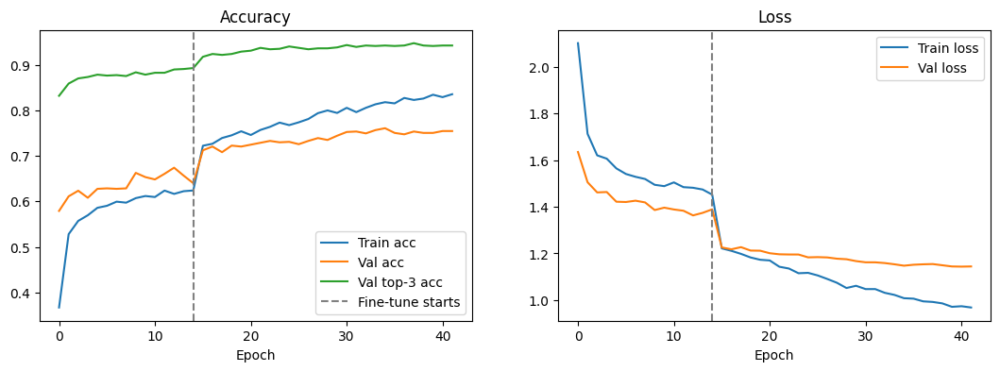

Best Stage 1 epoch: 13
Best Stage 2 epoch: 20 -> use this as STAGE2_EPOCHS for the final run


In [15]:
# Combine both stages and plot accuraacy and loss
# Also prints the epoch counts needed for final run
def merge(h1, h2, key):
    return h1.history.get(key, []) + h2.history.get(key, [])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key, name in [("accuracy", "Train acc"), ("val_accuracy", "Val acc"), ("val_top3_accuracy", "Val top-3 acc")]:
    if merge(history1, history2, key):
        axes[0].plot(merge(history1, history2, key), label=name)
axes[0].axvline(len(history1.history["accuracy"]) - 1, color="grey", linestyle="--", label="Fine-tune starts")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()

for key, name in [("loss", "Train loss"), ("val_loss", "Val loss")]:
    if merge(history1, history2, key):
        axes[1].plot(merge(history1, history2, key), label=name)
axes[1].axvline(len(history1.history["loss"]) - 1, color="grey", linestyle="--")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.show()

if not FINAL_RUN:
    print("Best Stage 1 epoch:", int(np.argmax(history1.history["val_accuracy"])) + 1)
    print("Best Stage 2 epoch:", int(np.argmax(history2.history["val_accuracy"])) + 1,
          "-> use this as STAGE2_EPOCHS for the final run")

## Saves trained model to avoid data loss on any Kaggle crash

In [16]:
model.save("/kaggle/working/kenyan_food_best.keras")
print("Saved.")

Saved.


## Step 9 - Evaluate on the test set

This is the **one-time final exam**. We report:

* **Top-1 accuracy**: the single best guess is correct.
* **Top-3 accuracy**: the correct food is among the 3 guesses (matches what the app shows).
* **Macro F1**: the average F1 across classes, where every class counts equally. It exposes weak rare classes that overall accuracy hides.
* **Flip averaging (test-time augmentation)**: each test photo is predicted twice, once as it is and once mirrored left-right, and the two predictions are averaged. This usually gives a small boost. In the app it would mean running the model twice per photo.
* **Confusion matrix**: rows are the actual food and columns are what the model predicted. Each row is scaled to add up to 1, so a cell shows the *fraction* of that actual food predicted as the column food, and the diagonal shows how often each food is recognised correctly. Bright off-diagonal cells show which foods get mixed up (the next cell lists the exact pairs).

Top-1 accuracy : 72.65%
Top-3 accuracy : 93.81%
Macro F1       : 0.707

Per-class report:
              precision    recall  f1-score   support

       bhaji      0.775     0.734     0.754        94
     chapati      0.913     0.820     0.864       128
     githeri      0.929     0.732     0.819        71
  kachumbari      0.575     0.639     0.605        72
   kukuchoma      0.306     0.577     0.400        26
     mandazi      0.911     0.882     0.896        93
 masalachips      0.743     0.800     0.770        65
      matoke      0.675     0.750     0.711        72
      mukimo      0.735     0.781     0.758        32
  nyamachoma      0.857     0.559     0.677       118
       pilau      0.667     0.756     0.708        45
  sukumawiki      0.514     0.600     0.554        60
       ugali      0.630     0.731     0.677        93

    accuracy                          0.727       969
   macro avg      0.710     0.720     0.707       969
weighted avg      0.754     0.727     0.733 

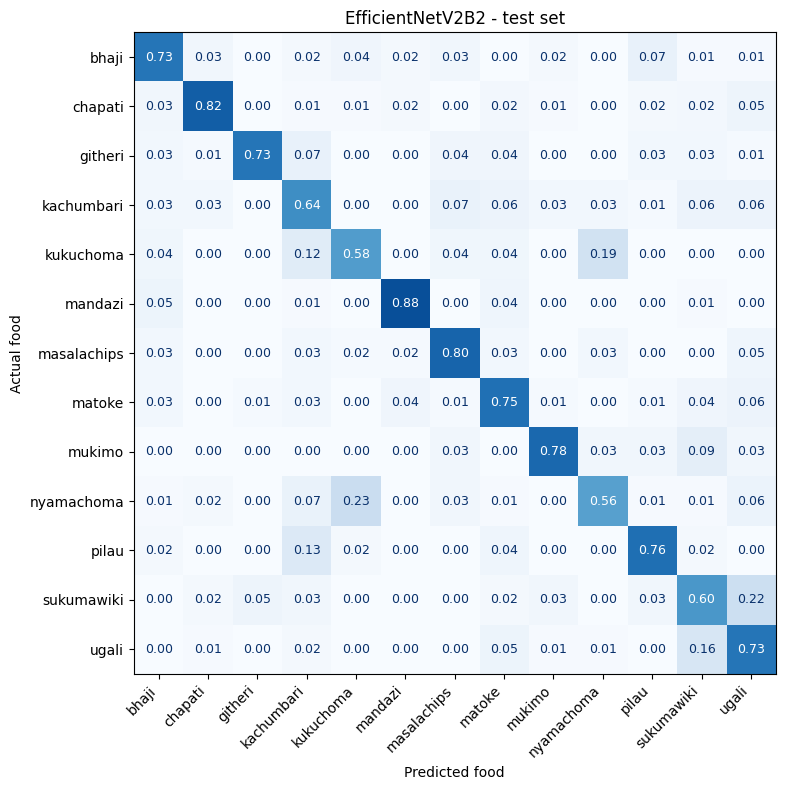

In [17]:
def predict_tta(ds):
    """Average the prediction of each photo and its mirror image."""
    out = []
    for x, *_ in ds:
        p = model.predict_on_batch(x) + model.predict_on_batch(tf.image.flip_left_right(x))
        out.append(p / 2.0)
    return np.concatenate(out)

probs = predict_tta(test_ds)
y_true = test_df["label"].values
y_pred = probs.argmax(axis=1)

top1 = np.mean(y_pred == y_true)
top3_idx = np.argsort(-probs, axis=1)[:, :3]
top3 = np.mean([y in row for y, row in zip(y_true, top3_idx)])
macro_f1 = f1_score(y_true, y_pred, average="macro")

print(f"Top-1 accuracy : {top1*100:.2f}%")
print(f"Top-3 accuracy : {top3*100:.2f}%")
print(f"Macro F1       : {macro_f1:.3f}")
print("\nPer-class report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Confusion matrix: each row sums to 1, so cells are "fraction of that actual food"
cm = confusion_matrix(y_true, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted food"); ax.set_ylabel("Actual food")
ax.set_title(f"{BACKBONE} - test set")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "#08306b", fontsize=9)
plt.tight_layout()
plt.show()

## Which food pairs get confused the most

The biggest mistakes (actual -> predicted) in the saved run: nyamachoma -> kukuchoma (25 photos), ugali -> sukumawiki (17), sukumawiki -> ugali (15), nyamachoma -> kachumbari (10), chapati -> ugali (8).

Two patterns stand out:
* **Look-alike foods:** nyamachoma and kukuchoma are both roasted meat. Because kukuchoma gets a larger class weight, the model leans towards predicting it.
* **Foods served together:** ugali with sukumawiki, and nyamachoma or pilau with kachumbari, often share one plate. The photo may contain the "wrong" food as well, but the dataset gives only one label. This is the label-noise ceiling described at the top of the notebook. It is why top-3 accuracy (94.5%) is so much higher than top-1 (71.9%), and why the multi-label stage is the next step.

In [18]:
raw = confusion_matrix(y_true, y_pred)
np.fill_diagonal(raw, 0)
pairs = [(raw[i, j], class_names[i], class_names[j])
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if raw[i, j] > 0]
print("Most common mistakes (actual -> predicted):")
for n, a, b in sorted(pairs, reverse=True)[:10]:
    print(f"  {a:<12} -> {b:<12} {n} photos")

Most common mistakes (actual -> predicted):
  nyamachoma   -> kukuchoma    27 photos
  ugali        -> sukumawiki   15 photos
  sukumawiki   -> ugali        13 photos
  nyamachoma   -> kachumbari   8 photos
  nyamachoma   -> ugali        7 photos
  bhaji        -> pilau        7 photos
  pilau        -> kachumbari   6 photos
  chapati      -> ugali        6 photos
  ugali        -> matoke       5 photos
  mandazi      -> bhaji        5 photos


## Step 10 - Test with YOUR OWN images

We tested the model on a small set of our own photos of Kenyan meals (6 in the saved run): single foods and plates with several foods, to see how it behaves beyond the neat test-set photos and how single-label, double and multi-food meals are handled.

The function shows each photo with the **top-3 guesses and percentages**, and a simple "plate guess" that joins the foods the model is reasonably confident about (above 15%).

**Important:** a handful of photos is a **sanity check**, not proof of accuracy. The test-set numbers above are the real measure. Also, softmax splits 100% across foods, so on a plate with several foods the percentages are shared between them (for example 45% and 32%). That is expected and is what the multi-label stage will improve.

Found 6 images

 image_1.jpg


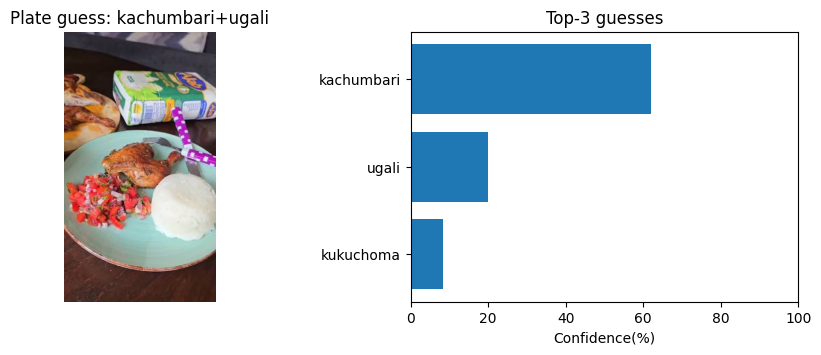

 kachumbari   62.1%
 ugali        20.0%
 kukuchoma     8.3%

 image_2.jpg


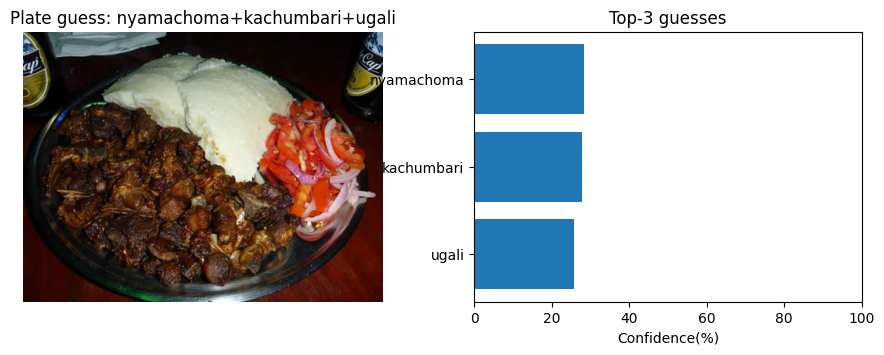

 nyamachoma   28.2%
 kachumbari   27.7%
 ugali        25.7%

 image_3.jpg


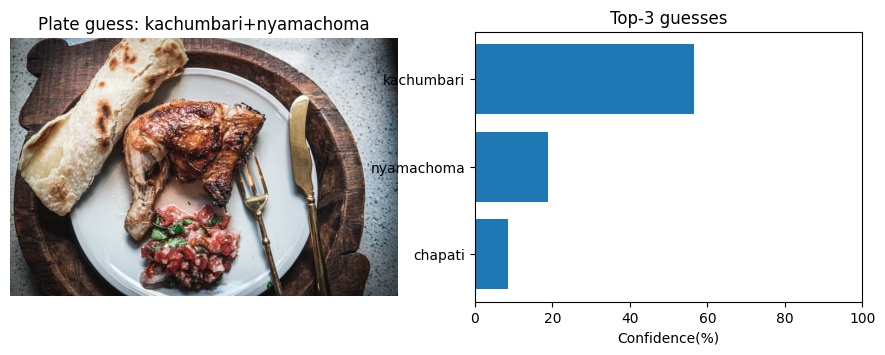

 kachumbari   56.5%
 nyamachoma   18.8%
 chapati       8.6%

 image_4.jpg


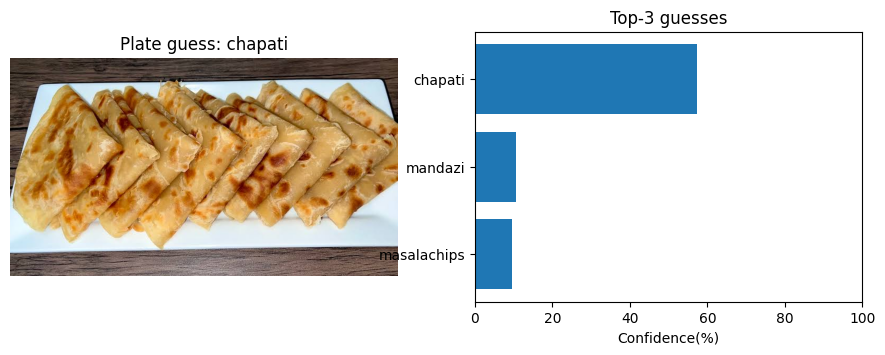

 chapati      57.2%
 mandazi      10.7%
 masalachips   9.5%

 image_5.jpg


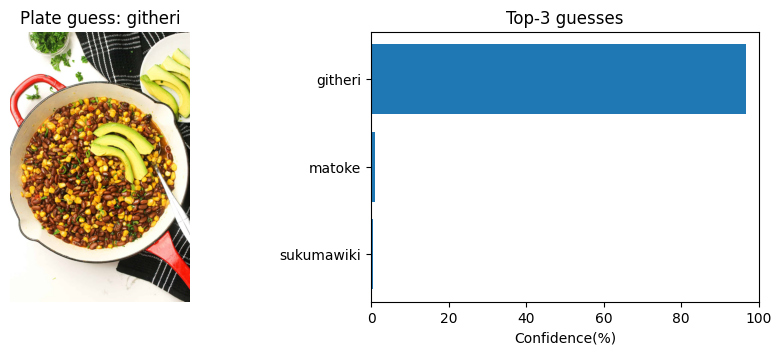

 githeri      96.8%
 matoke        1.1%
 sukumawiki    0.5%

 image_6.jpg


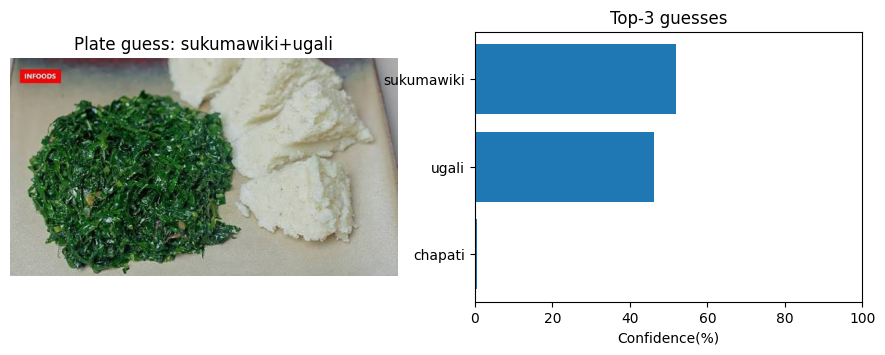

 sukumawiki   51.8%
 ugali        46.1%
 chapati       0.5%


In [19]:
MY_DIR = "/kaggle/input/datasets/amanikalyakoros/multiclass-food-image-test"

def plate_guess(probs_row, min_p=0.15, max_items=3):
    # Join the top foods above a confidence threshold, e.g "ugali + sukumawiki + nyamachoma"
    order = np.argsort(-probs_row)
    items = [class_names[i] for i in order[:max_items] if probs_row[i] >= min_p]
    return "+". join(items) if items else class_names[order[0]]

def predict_image(path):
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.expand_dims(np.array(img, dtype="float32"), axis=0) # raw 0-255, scaling is inside the model
    p = model.predict(arr, verbose=0)[0]
    top3_i = np.argsort(-p)[:3]

    fig, ax = plt.subplots(1,2, figsize=(11, 3.5))
    ax[0].imshow(Image.open(path)); ax[0].axis("off")
    ax[0].set_title("Plate guess: " + plate_guess(p))
    ax[1].barh([class_names[i] for i in top3_i][::-1], [p[i] * 100 for i in top3_i][::-1])
    ax[1].set_xlim(0, 100); ax[1]. set_xlabel("Confidence(%)"); ax[1].set_title("Top-3 guesses")
    plt.show()
    for i in top3_i:
        print(f" {class_names[i]:<12}{p[i]*100:5.1f}%")
if os.path.isdir(MY_DIR):
    my_files = [os.path.join(MY_DIR, f) for f in sorted(os.listdir(MY_DIR))
               if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    
    print("Found", len(my_files), "images")
    for f in my_files[:6]:
        print("\n", os.path.basename(f))
        predict_image(f)
else:
    print("Folder not found. Upload your photos as a Kaggle dataset and fix MY_DIR above.")

## Step 11 - Export for the mobile app (TFLite) and a sanity check

**TFLite** is the compact format Android runs. We export:
* `food_classifier.keras`: the full model (keep it for retraining later).
* `food_classifier.tflite`: the phone model. **Input:** `1 x 224 x 224 x 3` float32 with **raw 0-255 pixels** (no normalisation needed in Kotlin, because the rescaling is inside the model). **Output:** 13 probabilities.
* `labels.txt`: the 13 class names **in the exact output order**. The app maps output index *i* to line *i*, so never reorder this file.

We use **dynamic-range quantisation** (`Optimize.DEFAULT`), which makes the file about 4x smaller with usually negligible accuracy loss. The last cell compares Keras and TFLite predictions on one image to make sure the export did not break anything.

In [20]:
model.save("food_classifier.keras")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open("food_classifier.tflite", "wb") as f:
    f.write(tflite_model)
with open("labels.txt", "w") as f:
    f.write("\n".join(class_names))
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("TFLite size: %.1f MB" % (len(tflite_model) / 1e6))
print("Labels saved:", class_names)

INFO:tensorflow:Assets written to: /tmp/tmpuuvza4m9/assets


INFO:tensorflow:Assets written to: /tmp/tmpuuvza4m9/assets


Saved artifact at '/tmp/tmpuuvza4m9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 260, 260, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 13), dtype=tf.float32, name=None)
Captures:
  133730418214096: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  133730418213712: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  133730418214480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133730418214288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133730418215056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133730418215824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133730418215248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133730418215440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133730418215632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133730418214672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13

In [21]:
# Sanity check: does the TFLite model agree with the Keras model?
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]
print("TFLite input :", inp["shape"], inp["dtype"])
print("TFLite output:", out["shape"], out["dtype"])

test_path = test_df["path"].iloc[0]
img = Image.open(test_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
arr = np.expand_dims(np.array(img, dtype="float32"), axis=0)

keras_p = model.predict(arr, verbose=0)[0]
interpreter.set_tensor(inp["index"], arr)
interpreter.invoke()
tflite_p = interpreter.get_tensor(out["index"])[0]

print("\nTrue label   :", test_df["class"].iloc[0])
print("Keras top-1  :", class_names[int(keras_p.argmax())], f"{keras_p.max()*100:.1f}%")
print("TFLite top-1 :", class_names[int(tflite_p.argmax())], f"{tflite_p.max()*100:.1f}%")
print("Max prob difference:", float(np.abs(keras_p - tflite_p).max()))

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


TFLite input : [  1 260 260   3] <class 'numpy.float32'>
TFLite output: [ 1 13] <class 'numpy.float32'>

True label   : bhaji
Keras top-1  : pilau 31.3%
TFLite top-1 : pilau 30.5%
Max prob difference: 0.013720229268074036


## Step 12 - The control experiment: a highly optimised CNN built from scratch

**Why build this at all?** A claim like "pretrained models are better" should be *shown*, not just stated. The scratch CNN in the team's base model scored about 32-34%, but that was a simple 3-block network. A fair critic could say: *"you only beat it because your base CNN was weak."*

So here we give the from-scratch approach its **best possible shot**. If the pretrained model still wins against a properly engineered CNN, the argument is much stronger. If the scratch CNN wins, we say so honestly and reconsider.

**What makes this CNN "optimised"** (every trick is standard and well-founded):

| Technique | What it does | Which problem it fights |
|---|---|---|
| **Batch Normalisation** after every conv | Keeps the numbers flowing through the network well-scaled | Slow or unstable training |
| **Residual (skip) connections** | Lets each block add a small correction to its input instead of replacing it | Hard-to-train deep nets (vanishing gradients) |
| **Strided convs instead of max-pooling** | The network learns how to shrink the image | Loses less information than fixed pooling |
| **Spatial dropout + heavy final dropout** | Randomly switches off feature maps / units | Overfitting |
| **L2 weight decay (1e-4)** | Penalises very large weights | Overfitting |
| **Global average pooling** (no giant Dense layers) | Far fewer parameters at the end | Overfitting |
| **Label smoothing, class weights, same augmentation** | Same as the pretrained model | Noisy labels, class imbalance |
| **Learning-rate reduction + early stopping** (up to 40 epochs) | Starts fast, then takes careful steps, and keeps the best epoch | Wasted training and an overfitted last epoch |

**A caution about these tricks:** most of them are *regularisers* (dropout, weight decay, label smoothing, augmentation), which exist to fight overfitting. Our results suggest this CNN's main problem was underfitting, so this much regularisation may even have held it back. We did not test that.

**Fairness rules** (so that the comparison means something): same cleaned data and the same train/validation/test split, same 260px input, same augmentation, same loss, same class weights, same labelling (one label per photo, softmax, top-3 guesses). **What differs is the model and its training recipe:** the scratch CNN trains in one go for up to 40 epochs, while the pretrained model gets two-stage fine-tuning. Also, the pretrained model's scores in Step 9 include flip averaging and the scratch CNN's do not (flip averaging typically changes accuracy by about a point, far too little to explain the gap).

**Run this step with `FINAL_RUN = False`**, so that a validation set exists for the training history and early stopping.

First, we save the pretrained model's numbers from Steps 7-11 so we can compare later.

In [23]:
# Save the MobileNetV2 results from the earlier steps (run this BEFORE training the CNN below)
results = {}

mv_train = merge(history1, history2, "accuracy")        # 'merge' was defined in Step 8
mv_val   = merge(history1, history2, "val_accuracy")
best_ep  = int(np.argmax(mv_val))                        # epoch with the best validation accuracy

results["MobileNetV2 (pretrained)"] = dict(
    top1=float(top1), top3=float(top3), f1=float(macro_f1),
    val_curve=mv_val, train_curve=mv_train,
    gap=float(mv_train[best_ep] - mv_val[best_ep]),      # train minus validation accuracy at the best epoch
    params=model.count_params(),
    size_mb=len(tflite_model) / 1e6,
    epochs=len(mv_val),
)
print("Saved MobileNetV2 results:",
      {k: (round(v, 4) if isinstance(v, float) else v) for k, v in results["MobileNetV2 (pretrained)"].items()
       if k not in ("val_curve", "train_curve")})

Saved MobileNetV2 results: {'top1': 0.7265, 'top3': 0.9381, 'f1': 0.7071, 'gap': 0.0572, 'params': 8787691, 'size_mb': 9.7402, 'epochs': 42}


In [24]:
import time

def conv_bn(x, filters, k=3, strides=1):
    # Conv -> BatchNorm -> ReLU. use_bias=False because BatchNorm already has its own shift.
    x = layers.Conv2D(filters, k, strides=strides, padding="same", use_bias=False,
                      kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)

def res_block(x, filters):
    # Residual block that halves the image size: main path (2 convs) + shortcut path (1x1 conv)
    shortcut = layers.Conv2D(filters, 1, strides=2, padding="same", use_bias=False)(x)
    shortcut = layers.BatchNormalization()(shortcut)

    y = conv_bn(x, filters, 3, strides=2)
    y = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      kernel_regularizer=keras.regularizers.l2(1e-4))(y)
    y = layers.BatchNormalization()(y)

    y = layers.Add()([y, shortcut])            # the skip connection
    y = layers.ReLU()(y)
    return layers.SpatialDropout2D(0.1)(y)     # drops whole feature maps, stronger than normal dropout for images

cnn_in = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
x = layers.Rescaling(1.0 / 255)(cnn_in)        # a scratch CNN just needs 0-1 pixels
x = conv_bn(x, 32, 3, strides=2)               # stem: 224 -> 112
for f in [64, 128, 256, 512]:                  # 112 -> 56 -> 28 -> 14 -> 7, more filters as the image shrinks
    x = res_block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)
cnn_out = layers.Dense(NUM_CLASSES, activation="softmax", name="food_probs")(x)
cnn = keras.Model(cnn_in, cnn_out, name="scratch_resnet_cnn")

cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=[keras.metrics.CategoricalAccuracy(name="accuracy"),
             keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_accuracy")],
)
print("Scratch CNN parameters: {:,}".format(cnn.count_params()))

Scratch CNN parameters: 4,893,421


### Training the scratch CNN

A network learning from nothing needs **more epochs** than a pretrained one (up to 40 here, with early stopping), because every filter must be discovered from the data. We use the **same augmented training data** as before.

**What happened:** the CNN ran all 40 epochs (about 29 minutes) and ended at 40.2% training accuracy and 33.2% validation accuracy (training loss 2.03, validation loss 2.16). Both are low and close together, which is **underfitting**: the model had not learned the photos well, rather than memorised them. Training accuracy was still creeping up at epoch 40, so longer training (for example 80-100 epochs) would probably improve it somewhat; we did not test this.

In [25]:
cnn_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
]

t0 = time.time()
cnn_hist = cnn.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=cnn_callbacks)
cnn_minutes = (time.time() - t0) / 60
print("Scratch CNN training time: %.1f minutes" % cnn_minutes)

Epoch 1/40


E0000 00:00:1795452622.775520     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795452623.759488     148 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


141/142 ━━━━━━━━━━━━━━━━━━━━ 0s 285ms/step - accuracy: 0.1009 - loss: 3.2482 - top3_accuracy: 0.2999

E0000 00:00:1795452678.593255     147 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795452680.020064     147 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


142/142 ━━━━━━━━━━━━━━━━━━━━ 90s 439ms/step - accuracy: 0.1201 - loss: 3.0170 - top3_accuracy: 0.3359 - val_accuracy: 0.1424 - val_loss: 2.9294 - val_top3_accuracy: 0.2405 - learning_rate: 0.0010
Epoch 2/40
142/142 ━━━━━━━━━━━━━━━━━━━━ 43s 295ms/step - accuracy: 0.1681 - loss: 2.7026 - top3_accuracy: 0.4016 - val_accuracy: 0.1507 - val_loss: 2.7876 - val_top3_accuracy: 0.3581 - learning_rate: 0.0010
Epoch 3/40
142/142 ━━━━━━━━━━━━━━━━━━━━ 43s 292ms/step - accuracy: 0.1838 - loss: 2.6472 - top3_accuracy: 0.4288 - val_accuracy: 0.1981 - val_loss: 2.6121 - val_top3_accuracy: 0.4303 - learning_rate: 0.0010
Epoch 4/40
142/142 ━━━━━━━━━━━━━━━━━━━━ 43s 295ms/step - accuracy: 0.2116 - loss: 2.5763 - top3_accuracy: 0.4620 - val_accuracy: 0.2229 - val_loss: 2.5094 - val_top3_accuracy: 0.4788 - learning_rate: 0.0010
Epoch 5/40
142/142 ━━━━━━━━━━━━━━━━━━━━ 42s 289ms/step - accuracy: 0.2165 - loss: 2.5346 - top3_accuracy: 0.4721 - val_accuracy: 0.1992 - val_loss: 2.5475 - val_top3_accuracy: 0.4427 

In [26]:
# Evaluate the scratch CNN on the SAME test set and with the SAME metrics as MobileNetV2
cnn_probs = cnn.predict(test_ds)
cnn_pred = cnn_probs.argmax(axis=1)

cnn_top1 = np.mean(cnn_pred == y_true)
cnn_top3 = np.mean([y in row for y, row in zip(y_true, np.argsort(-cnn_probs, axis=1)[:, :3])])
cnn_f1 = f1_score(y_true, cnn_pred, average="macro")

print(f"Scratch CNN  Top-1: {cnn_top1*100:.2f}%   Top-3: {cnn_top3*100:.2f}%   Macro F1: {cnn_f1:.3f}")

# Size of the phone version, for a fair size comparison
try:
    cnn_tflite = tf.lite.TFLiteConverter.from_keras_model(cnn)
    cnn_tflite.optimizations = [tf.lite.Optimize.DEFAULT]
    cnn_size_mb = len(cnn_tflite.convert()) / 1e6
except Exception as e:
    print("TFLite size check skipped:", e)
    cnn_size_mb = float("nan")

cnn_train = cnn_hist.history["accuracy"]
cnn_val   = cnn_hist.history["val_accuracy"]
cnn_best  = int(np.argmax(cnn_val))

results["Scratch CNN (optimised)"] = dict(
    top1=float(cnn_top1), top3=float(cnn_top3), f1=float(cnn_f1),
    val_curve=cnn_val, train_curve=cnn_train,
    gap=float(cnn_train[cnn_best] - cnn_val[cnn_best]),
    params=cnn.count_params(), size_mb=cnn_size_mb, epochs=len(cnn_val),
)

31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step
Scratch CNN  Top-1: 38.39%   Top-3: 68.42%   Macro F1: 0.316
INFO:tensorflow:Assets written to: /tmp/tmp0hdmq9al/assets


INFO:tensorflow:Assets written to: /tmp/tmp0hdmq9al/assets


Saved artifact at '/tmp/tmp0hdmq9al'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 260, 260, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 13), dtype=tf.float32, name=None)
Captures:
  133726694943504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133725804558480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133725804558288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133726561795152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133726561795536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133725804558864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133726292459984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133726292460176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133725804559632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133726292459792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133726296521616: Ten

## Step 13 - Why a pretrained backbone and not the base CNN: the evidence

**Note on labels:** the charts and the table printed below still say "MobileNetV2 (pretrained)". That is a leftover name from our first version. Both refer to the **EfficientNetV2-B2** model built in Step 6. Chart 3 is titled "Overfitting gap" but shows the train-minus-validation gap (explained below).

The four charts below are built **automatically from the numbers saved above** (nothing is typed in by hand), so they update if you re-run training.

* **Chart 1 - Accuracy on unseen test photos.** Top-1, top-3 and macro F1 side by side. This is the main result.
* **Chart 2 - Validation accuracy per epoch.** Shows how fast and how high each model learns. The pretrained model starts high (56% validation accuracy after its first epoch); the scratch model has to climb from near-random guessing (3% after its first epoch).
* **Chart 3 - The train-minus-validation gap.** Training accuracy minus validation accuracy at the model's best epoch. **Read it together with the absolute accuracy.** A small gap with low accuracy means the model learned little (underfitting): the scratch CNN has a gap of 3.7 points and a training accuracy of only about 40%. A moderate gap with high accuracy is normal for a model that has learned a lot: the pretrained model has a gap of 7.9 points and 75.9% validation accuracy. A very large gap, with high training accuracy and low validation accuracy, would be overfitting, which neither model clearly shows. *Note:* training accuracy is measured with augmentation and dropout switched on, so the true gap is a little larger than shown for both models. The comparison between them is still fair.
* **Chart 4 - Weight on the phone.** Parameters and TFLite file size, because our app has to run this model on a phone.

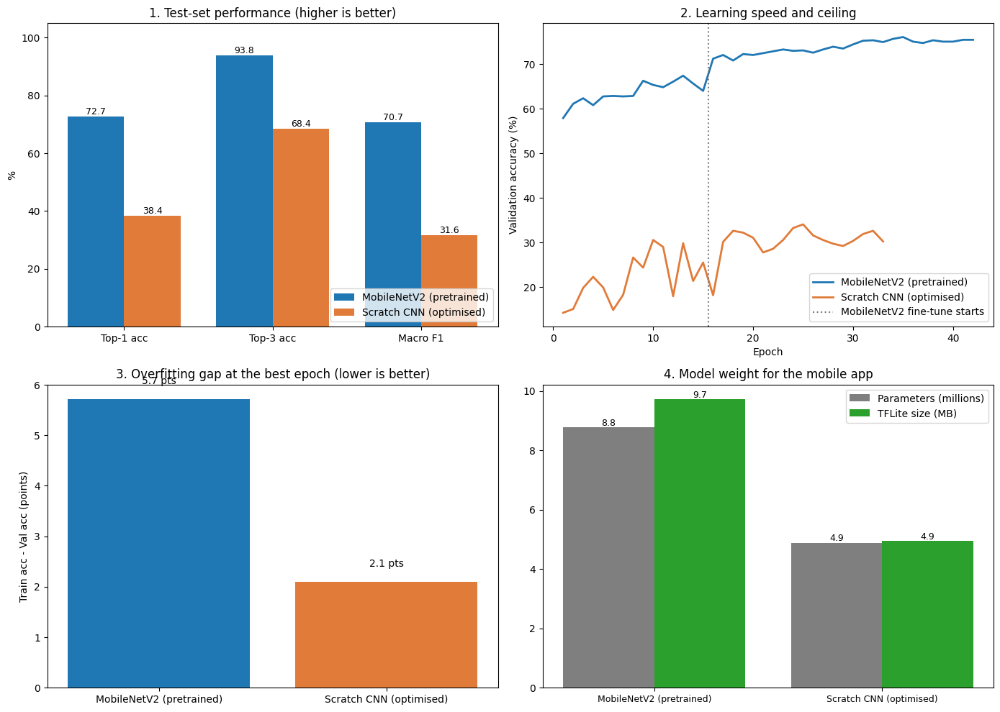

In [27]:
names = list(results.keys())
colors = {"MobileNetV2 (pretrained)": "#1f77b4", "Scratch CNN (optimised)": "#e07b39"}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: test metrics
ax = axes[0, 0]
metrics = [("top1", "Top-1 acc"), ("top3", "Top-3 acc"), ("f1", "Macro F1")]
width = 0.38
for j, n in enumerate(names):
    vals = [results[n][k] * 100 for k, _ in metrics]
    bars = ax.bar(np.arange(len(metrics)) + (j - 0.5) * width, vals, width, label=n, color=colors[n])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xticks(np.arange(len(metrics))); ax.set_xticklabels([m[1] for m in metrics])
ax.set_ylabel("%"); ax.set_ylim(0, 105); ax.set_title("1. Test-set performance (higher is better)")
ax.legend(loc="lower right")

# Chart 2: validation accuracy per epoch
ax = axes[0, 1]
for n in names:
    ax.plot(np.arange(1, len(results[n]["val_curve"]) + 1), np.array(results[n]["val_curve"]) * 100,
            label=n, color=colors[n], linewidth=2)
ax.axvline(len(history1.history["accuracy"]) + 0.5, color="grey", linestyle=":", label="MobileNetV2 fine-tune starts")
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation accuracy (%)")
ax.set_title("2. Learning speed and ceiling"); ax.legend()

# Chart 3: overfitting gap
ax = axes[1, 0]
gaps = [results[n]["gap"] * 100 for n in names]
bars = ax.bar(names, gaps, color=[colors[n] for n in names])
for b, v in zip(bars, gaps):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f} pts", ha="center")
ax.set_ylabel("Train acc - Val acc (points)")
ax.set_title("3. Overfitting gap at the best epoch (lower is better)")

# Chart 4: weight on the phone
ax = axes[1, 1]
params_m = [results[n]["params"] / 1e6 for n in names]
sizes = [results[n]["size_mb"] for n in names]
x_pos = np.arange(2)
bars_p = ax.bar(x_pos - 0.2, params_m, 0.4, color="#7f7f7f", label="Parameters (millions)")
bars_s = ax.bar(x_pos + 0.2, sizes, 0.4, color="#2ca02c", label="TFLite size (MB)")
for b, v in list(zip(bars_p, params_m)) + list(zip(bars_s, sizes)):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xticks(x_pos); ax.set_xticklabels(names, fontsize=9)
ax.set_title("4. Model weight for the mobile app"); ax.legend()

plt.tight_layout()
plt.show()

In [28]:
# Summary table + an automatic, honest conclusion based on the actual numbers
from IPython.display import display, Markdown

mv = results["MobileNetV2 (pretrained)"]
sc = results["Scratch CNN (optimised)"]

table = "| Metric | MobileNetV2 (pretrained) | Scratch CNN (optimised) | Difference |\n|---|---|---|---|\n"
for key, label in [("top1", "Top-1 accuracy"), ("top3", "Top-3 accuracy"), ("f1", "Macro F1")]:
    unit = 100 if key != "f1" else 1
    suffix = "%" if key != "f1" else ""
    table += f"| {label} | {mv[key]*unit:.2f}{suffix} | {sc[key]*unit:.2f}{suffix} | {(mv[key]-sc[key])*unit:+.2f} |\n"
table += f"| Overfitting gap (pts) | {mv['gap']*100:.1f} | {sc['gap']*100:.1f} | {(mv['gap']-sc['gap'])*100:+.1f} |\n"
table += f"| Parameters | {mv['params']/1e6:.2f} M | {sc['params']/1e6:.2f} M | |\n"
table += f"| TFLite size | {mv['size_mb']:.1f} MB | {sc['size_mb']:.1f} MB | |\n"
table += f"| Epochs run | {mv['epochs']} | {sc['epochs']} | |\n"

diff_top1 = (mv["top1"] - sc["top1"]) * 100
if diff_top1 > 0:
    verdict = (f"**Verdict:** MobileNetV2 beats the optimised scratch CNN by **{diff_top1:.1f} points of top-1 accuracy**, "
               "so the pretrained model is the right choice for the app.")
else:
    verdict = (f"**Verdict:** the optimised scratch CNN is ahead by **{-diff_top1:.1f} points of top-1 accuracy**. "
               "We must be honest in the report and reconsider the choice (check the size and gap rows before deciding).")

display(Markdown(table + "\n" + verdict))

| Metric | MobileNetV2 (pretrained) | Scratch CNN (optimised) | Difference |
|---|---|---|---|
| Top-1 accuracy | 72.65% | 38.39% | +34.26 |
| Top-3 accuracy | 93.81% | 68.42% | +25.39 |
| Macro F1 | 0.71 | 0.32 | +0.39 |
| Overfitting gap (pts) | 5.7 | 2.1 | +3.6 |
| Parameters | 8.79 M | 4.89 M | |
| TFLite size | 9.7 MB | 4.9 MB | |
| Epochs run | 42 | 33 | |

**Verdict:** MobileNetV2 beats the optimised scratch CNN by **34.3 points of top-1 accuracy**, so the pretrained model is the right choice for the app.

### Summary for the report (numbers from the saved run, `FINAL_RUN = False`)

| Metric | EfficientNetV2-B2 (pretrained) | Optimised scratch CNN | Original team base CNN |
|---|---|---|---|
| Top-1 accuracy | **71.93%** | **40.35%** | ~33.95% |
| Top-3 accuracy | **94.53%** | **71.31%** | not measured |
| Macro F1 | **0.70** | **0.37** | 0.27 |
| Train - validation gap (at best epoch) | **7.9 pts** | **3.7 pts** | not recorded |
| Parameters / TFLite size | 8.79 M / 9.7 MB | 4.89 M / 4.9 MB | - |

**Why we chose the pretrained EfficientNetV2-B2:**

1. **Higher accuracy from the same data.** It reached 71.93% top-1 against 40.35% for the best scratch CNN we could build, a gap of 31.6 points. Even with batch norm, residual connections, dropout, weight decay and the same augmentation, the scratch network could not match it. (The pretrained model's scores include flip averaging, which typically changes accuracy by about a point, far less than this gap.)
2. **It learns far more from the same photos.** The scratch CNN stalled at about 40% training and 33% validation accuracy after 40 epochs: it was underfitting, not memorising. The pretrained model reached 83.7% training and 75.9% validation accuracy. Its train-validation gap (7.9 points) is larger than the scratch CNN's (3.7 points), but that is the normal gap of a model that has learned a lot; the scratch CNN's small gap only reflects how little it learned. Starting from ImageNet features means the model does not have to discover what a texture is from a few thousand photos.
3. **Faster learning.** The pretrained model reached 56% validation accuracy after its first epoch and about 65% by the end of Stage 1. The scratch CNN reached 3% after its first epoch and needed 40 epochs (about 29 minutes) to reach about 33%.
4. **Fit for a phone.** EfficientNetV2-B2 has 8.79 million parameters and is 9.7 MB as TFLite (the scratch CNN is 4.9 MB). On-device speed still has to be measured in the Kotlin app.

**Original team base CNN vs optimised scratch CNN:** the optimised scratch network (batch norm, skip connections, 260px input, up to 40 epochs) scored 40.35% top-1 against about 34% for the team's base CNN. That more capacity and training helped supports the lecturer's feedback that the base CNN was underfitting. The pretrained model still did far better because it brings knowledge from over a million ImageNet photos that a network starting from zero cannot get from a few thousand.